# PaySim: from the data audit to generator and graph experiments
**Shuveccha Barua | Advanced Topics in AI**

My main question is whether historical graph information improves fraud detection, and whether that answer depends on the simulator and the time period.





## 1. Setup, data location and requirements





In [33]:
%pip install -q duckdb pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import uuid
import duckdb
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

def sql_text(value):
    """Quote a SQL string literal, including paths that contain apostrophes."""
    return "'" + str(value).replace("'", "''") + "'"

def sql_name(value):
    """Quote a SQL column identifier."""
    return '"' + str(value).replace('"', '""') + '"'

def run_sql(label, sql, fetch=True):
    """Run an audit query; only small aggregate results are fetched into pandas."""
    result = con.execute(sql)
    return result.df() if fetch else None

def save_table(table, name):
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=False)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

print("Python", platform.python_version(), "| DuckDB", duckdb.__version__, "| pandas", pd.__version__)

Python 3.13.7 | DuckDB 1.4.4 | pandas 2.3.3


In [35]:
# Project paths and run settings.
PROJECT_ROOT = Path.cwd().resolve()


DATA_PATH = Path(os.environ.get("PAYSIM_CSV", "D:paysim dataset.csv")).expanduser()
USE_FILE_PICKER_FALLBACK = False   # only used when DATA_PATH does not exist

if not DATA_PATH.is_file() and USE_FILE_PICKER_FALLBACK:
    print(f"CSV not found at {DATA_PATH}. Trying a file picker as a fallback.")
    selected = ""
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        selected = filedialog.askopenfilename(
            title="Select the PaySim CSV file",
            filetypes=[("CSV files", "*.csv"), ("All files", "*.*")],
        )
        root.destroy()
    except Exception:
        selected = ""
    if not selected:
        try:
            selected = input("Paste the full path to the PaySim CSV (leave blank to cancel): ").strip().strip('"')
        except Exception:
            selected = ""
    if selected:
        DATA_PATH = Path(selected).expanduser()

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"PaySim CSV not found: {DATA_PATH}. Set PAYSIM_CSV or edit DATA_PATH in this cell."
    )
DATA_PATH = DATA_PATH.resolve()
print("Using CSV:", DATA_PATH.name)

# MAX_STEP=None runs the complete dataset.
MAX_STEP = None
WINDOWS = (6, 24, 48)
MEMORY_LIMIT = "4GB"
THREADS = 4
FORCE_REBUILD_CACHE = False

Using CSV: paysim dataset.csv


In [36]:
# Check the file 
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV not found: {DATA_PATH}. Edit DATA_PATH in the paths cell."
    )

if MAX_STEP is not None and (
    not isinstance(MAX_STEP, int)
    or isinstance(MAX_STEP, bool)
    or MAX_STEP < 0
):
    raise ValueError("MAX_STEP must be None or a nonnegative integer.")

if any(not isinstance(w, int) or w <= 0 for w in WINDOWS) or 24 not in WINDOWS:
    raise ValueError("Use positive integer windows including 24 hours.")

if not isinstance(THREADS, int) or THREADS < 1:
    raise ValueError("THREADS must be a positive integer.")


# Create a separate results folder
mode = "full" if MAX_STEP is None else f"through_step_{MAX_STEP}"

run_id = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:6]
)

RESULTS_DIR = PROJECT_ROOT / "results" / f"paysim_week3_{mode}_{run_id}"
FIGURES_DIR = RESULTS_DIR / "figures"
CACHE_DIR = PROJECT_ROOT / "data" / "interim" / "paysim_audit_cache"
TEMP_DIR = RESULTS_DIR / "duckdb_tmp"

for directory in [FIGURES_DIR, CACHE_DIR, TEMP_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# Open and configuration of DuckDB
if "con" in globals():
    con.close()

con = duckdb.connect()
con.execute(f"SET memory_limit = {sql_text(MEMORY_LIMIT)}")
con.execute(f"SET threads = {THREADS}")
con.execute(f"SET temp_directory = {sql_text(TEMP_DIR.as_posix())}")
con.execute("SET preserve_insertion_order = false")


# Confirm the selected locations
print("Source file:", DATA_PATH.name)
print("Results folder:", RESULTS_DIR.relative_to(PROJECT_ROOT))

if MAX_STEP is not None:
    print(
        "PARTIAL TIME PREFIX: use for code checks, "
        "not full-dataset conclusions."
    )

Source file: paysim dataset.csv
Results folder: results\paysim_week3_full_20261022T174916Z_bae4c1


## 2. Load and validate the data

The source file is checked before analysis: required columns, missing values in every column, valid whole-hour
steps, nonnegative finite amounts, nonblank account IDs and binary labels. Invalid core values stop the run;
records are not silently removed or filled. Missing optional balance fields are reported without using them as features.

A SHA-256 fingerprint identifies the CSV and its reusable Parquet cache. Values remain text until validation,
so an invalid label such as `0.5` cannot be rounded into a valid one. Detailed checks are saved as CSVs.
The overview below describes the selected data; `MAX_STEP` is only an optional debugging time limit.



In [37]:
source_stat_before = DATA_PATH.stat()
source_hash = sha256_file(DATA_PATH)
source_stat_after = DATA_PATH.stat()
if (source_stat_before.st_size, source_stat_before.st_mtime_ns) != (source_stat_after.st_size, source_stat_after.st_mtime_ns):
    raise RuntimeError("The CSV changed while hashing. Stop editing it and rerun.")

CACHE_VERSION = "raw_v2"
CACHE_PATH = CACHE_DIR / f"{CACHE_VERSION}_{source_hash}.parquet"
CACHE_META = CACHE_PATH.with_suffix(".json")
expected_cache = {"schema_version": CACHE_VERSION, "source_sha256": source_hash,
                  "source_bytes": source_stat_after.st_size}
cache_ok = False
if CACHE_PATH.is_file() and CACHE_META.is_file() and not FORCE_REBUILD_CACHE:
    try:
        cached_meta = json.loads(CACHE_META.read_text(encoding="utf-8"))
        cache_ok = all(cached_meta.get(k) == v for k, v in expected_cache.items())
    except (ValueError, OSError):
        cache_ok = False

if not cache_ok:
    temporary_cache = CACHE_PATH.with_name(CACHE_PATH.stem + ".building_" + uuid.uuid4().hex + ".parquet")
    try:
        run_sql("CSV to Parquet cache", f"""
            COPY (SELECT * FROM read_csv({sql_text(DATA_PATH.as_posix())},
                header=true, all_varchar=true, ignore_errors=false))
            TO {sql_text(temporary_cache.as_posix())} (FORMAT PARQUET, COMPRESSION ZSTD)
        """, fetch=False)
        after_copy = DATA_PATH.stat()
        if (after_copy.st_size, after_copy.st_mtime_ns) != (source_stat_after.st_size, source_stat_after.st_mtime_ns):
            raise RuntimeError("CSV changed during cache creation; rerun with a stable input file.")
        temporary_cache.replace(CACHE_PATH)
        CACHE_META.write_text(json.dumps(expected_cache, indent=2), encoding="utf-8")
    finally:
        if temporary_cache.exists():
            temporary_cache.unlink()
else:
    print("Reusing cache for matching source SHA-256:", source_hash[:16])

con.execute(f"CREATE OR REPLACE TEMP VIEW raw AS SELECT * FROM read_parquet({sql_text(CACHE_PATH.as_posix())})")
schema = con.execute("DESCRIBE raw").df()
save_table(schema, "source_schema")
CORE = {"step", "type", "amount", "nameOrig", "nameDest", "isFraud"}
STANDARD = CORE | {"oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFlaggedFraud"}
actual_columns = set(schema["column_name"])
if CORE - actual_columns:
    raise ValueError(f"Required columns missing: {sorted(CORE - actual_columns)}")
HAS_FLAG = "isFlaggedFraud" in actual_columns
if STANDARD - actual_columns:
    print("Absent optional columns:", sorted(STANDARD - actual_columns))

Reusing cache for matching source SHA-256: 16910f90577b0d98


In [38]:
#Missingness and core-value validation
null_expressions = [f"COUNT(*) FILTER (WHERE {sql_name(c)} IS NULL) AS {sql_name(c)}" for c in schema["column_name"]]
nulls = run_sql("All-column missingness", "SELECT " + ", ".join(null_expressions) + " FROM raw")
missingness = nulls.T.reset_index()
missingness.columns = ["column", "missing_count"]
save_table(missingness, "missingness_all_columns")

step_value = 'TRY_CAST(step AS DOUBLE)'
amount_value = 'TRY_CAST(amount AS DOUBLE)'
label_value = 'TRY_CAST(isFraud AS DOUBLE)'
conditions = {
    "invalid_step": f"{step_value} IS NULL OR NOT isfinite({step_value}) OR {step_value} < 0 OR {step_value} > 2147483647 OR {step_value} != floor({step_value})",
    "invalid_amount": f"{amount_value} IS NULL OR NOT isfinite({amount_value}) OR {amount_value} < 0",
    "invalid_fraud_label": f"{label_value} IS NULL OR {label_value} NOT IN (0, 1)",
    "missing_or_blank_type": "type IS NULL OR length(trim(type)) = 0",
    "missing_or_blank_sender": "nameOrig IS NULL OR length(trim(nameOrig)) = 0",
    "missing_or_blank_receiver": "nameDest IS NULL OR length(trim(nameDest)) = 0",
}
if HAS_FLAG:
    conditions["invalid_existing_flag"] = "TRY_CAST(isFlaggedFraud AS DOUBLE) IS NULL OR TRY_CAST(isFlaggedFraud AS DOUBLE) NOT IN (0, 1)"
checks = run_sql("Core validation", "SELECT COUNT(*) AS rows, " + ", ".join(
    f"COUNT(*) FILTER (WHERE {condition}) AS {sql_name(name)}" for name, condition in conditions.items()
) + " FROM raw")
quality = checks.drop(columns="rows").T.reset_index()
quality.columns = ["check", "count"]
save_table(quality, "data_quality")
if int(checks.loc[0, "rows"]) == 0:
    raise ValueError("The source CSV has no transactions.")
if quality["count"].sum() > 0:
    raise ValueError("Invalid core values found. Inspect data_quality.csv; no records were removed or filled.")

flag_selection = ", CAST(TRY_CAST(isFlaggedFraud AS DOUBLE) AS TINYINT) AS isFlaggedFraud" if HAS_FLAG else ""
con.execute(f"""CREATE OR REPLACE TEMP VIEW paysim_all AS
    SELECT CAST(TRY_CAST(step AS DOUBLE) AS INTEGER) AS step, type,
           CAST(amount AS DOUBLE) AS amount, nameOrig, nameDest,
           CAST(TRY_CAST(isFraud AS DOUBLE) AS TINYINT) AS isFraud {flag_selection}
    FROM raw""")
time_filter = "" if MAX_STEP is None else f"WHERE step <= {MAX_STEP}"
con.execute(f"CREATE OR REPLACE TEMP VIEW paysim AS SELECT * FROM paysim_all {time_filter}")
if con.execute("SELECT COUNT(*) FROM paysim").fetchone()[0] == 0:
    raise ValueError("No rows remain in the selected time prefix. Increase MAX_STEP.")


quality_summary = pd.DataFrame([
    ("Rows checked in the full source", int(checks.loc[0, "rows"])),
    ("Missing cells across all source columns", int(missingness["missing_count"].sum())),
    ("Invalid core values", int(quality["count"].sum())),
], columns=["check", "count"])
display(quality_summary)
if missingness["missing_count"].sum() > 0:
    display(missingness[missingness["missing_count"] > 0])
save_table(quality_summary, "quality_summary")

,check,count
0,Rows checked in the full source,6362620
1,Missing cells across all source columns,0
2,Invalid core values,0


In [39]:
#Dataset overview
overview = run_sql("Overview", """
    SELECT COUNT(*) AS transactions, MIN(step) AS first_step, MAX(step) AS last_step,
           COUNT(DISTINCT step) AS observed_steps, SUM(isFraud) AS fraud,
           100.0 * AVG(isFraud) AS fraud_rate_pct,
           COUNT(DISTINCT nameOrig) AS unique_senders,
           COUNT(DISTINCT nameDest) AS unique_receivers
    FROM paysim
""")
display(overview.T.rename(columns={0: "value"}))
save_table(overview, "overview")
n = int(overview.loc[0, "transactions"])
first_step = int(overview.loc[0, "first_step"])
last_step = int(overview.loc[0, "last_step"])

by_step = run_sql("Hourly aggregates", """
    SELECT step, COUNT(*) AS transactions, SUM(isFraud) AS fraud,
           SUM(amount) AS total_amount FROM paysim GROUP BY step ORDER BY step
""")

,value
transactions,"6,362,620.0000"
first_step,1.0000
last_step,743.0000
observed_steps,743.0000
fraud,"8,213.0000"
fraud_rate_pct,0.1291
unique_senders,"6,353,307.0000"
unique_receivers,"2,722,362.0000"


## 3. Fraud by transaction type

Counts show where transactions and fraud cases occur; rates show the fraction of each type labelled fraudulent.
These answer different questions. The first chart uses a logarithmic count scale to show types of different sizes.
Fraud labels are used here for description, not to calculate graph history or choose split boundaries.



,type,transactions,fraud,fraud_rate_pct,share_of_all_fraud_pct
0,CASH_OUT,2237500,"4,116.0000",0.1840,50.1157
1,PAYMENT,2151495,0.0000,0.0000,0.0000
2,CASH_IN,1399284,0.0000,0.0000,0.0000
3,TRANSFER,532909,"4,097.0000",0.7688,49.8843
4,DEBIT,41432,0.0000,0.0000,0.0000


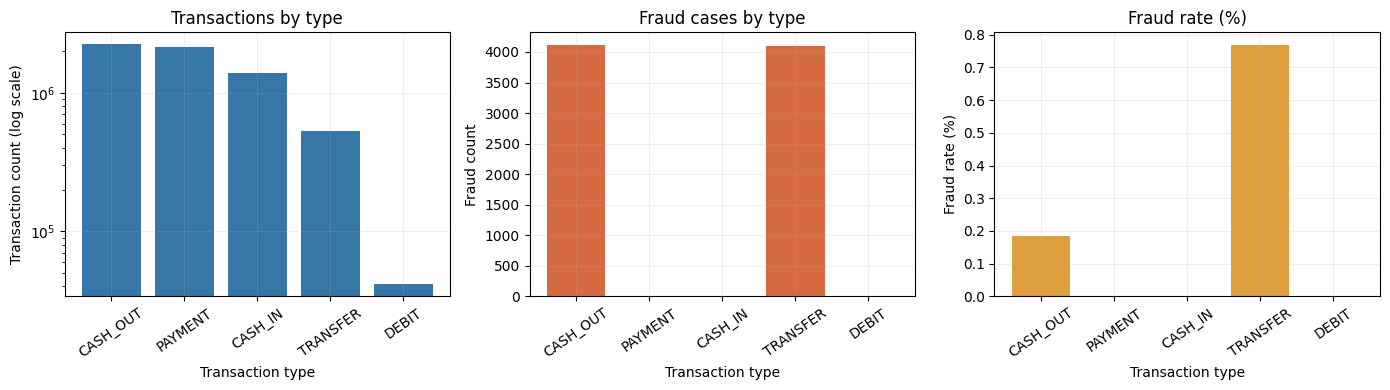

In [40]:
#Fraud by transaction type
fraud_by_type = run_sql("Fraud by transaction type", """
    SELECT type, COUNT(*) AS transactions, SUM(isFraud) AS fraud,
           100.0*AVG(isFraud) AS fraud_rate_pct,
           100.0*SUM(isFraud)/NULLIF(SUM(SUM(isFraud)) OVER (),0) AS share_of_all_fraud_pct
    FROM paysim GROUP BY type ORDER BY transactions DESC
""")
display(fraud_by_type)
save_table(fraud_by_type, "fraud_by_type")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

columns = ["transactions", "fraud", "fraud_rate_pct"]
titles = [
    "Transactions by type",
    "Fraud cases by type",
    "Fraud rate (%)"
]
colors = ["#3677A8", "#D66B42", "#E09F3E"]

for ax, column, title, color in zip(axes, columns, titles, colors):
    ax.bar(
        fraud_by_type["type"],
        fraud_by_type[column],
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel("Transaction type")
    ax.tick_params(axis="x", rotation=35)

axes[0].set_yscale("log")
axes[0].set_ylabel("Transaction count (log scale)")
axes[1].set_ylabel("Fraud count")
axes[2].set_ylabel("Fraud rate (%)")

save_figure("fraud_by_type")

In [41]:
# How much does a type rule actually narrow the problem? (descriptive; labels used for description only)
tc_mask = fraud_by_type["type"].isin(["TRANSFER", "CASH_OUT"])
tc_tx = int(fraud_by_type.loc[tc_mask, "transactions"].sum())
tc_fraud = int(fraud_by_type.loc[tc_mask, "fraud"].sum())
overall_rate = 100.0 * int(fraud_by_type["fraud"].sum()) / int(fraud_by_type["transactions"].sum())
tc_rate = 100.0 * tc_fraud / tc_tx
type_rule_summary = pd.DataFrame([
    ("All transactions", int(fraud_by_type["transactions"].sum()), int(fraud_by_type["fraud"].sum()), overall_rate),
    ("TRANSFER + CASH_OUT only", tc_tx, tc_fraud, tc_rate),
], columns=["rows", "transactions", "fraud", "fraud_rate_pct"])
display(type_rule_summary)
save_table(type_rule_summary, "type_rule_summary")
print(f"Restricting to TRANSFER/CASH_OUT keeps {100*tc_fraud/max(int(fraud_by_type['fraud'].sum()),1):.1f}% of fraud "
      f"but raises the fraud rate only from {overall_rate:.2f}% to {tc_rate:.4f}% ({tc_rate/overall_rate:.4f}x).")

,rows,transactions,fraud,fraud_rate_pct
0,All transactions,6362620,8213,0.1291
1,TRANSFER + CASH_OUT only,2770409,8213,0.2965


Restricting to TRANSFER/CASH_OUT keeps 100.0% of fraud but raises the fraud rate only from 0.13% to 0.2965% (2.2966x).


### Section note — transaction types
Read the counts and rates together. A type may contain most fraud while most transactions of that type are still legitimate. The old PaySim file concentrated fraud in TRANSFER and CASH_OUT; check this again for each generated run instead of assuming that every fork uses the same fraud mechanism.

## 4. Transaction and fraud patterns over time

Inspect volume, fraud counts and fraud rates separately. Changes over time can make a chronological test set
different from training. Missing steps inside the observed range are shown as zero recorded transactions;
their fraud rate remains undefined. Simulation hours are not real calendar timestamps.



Missing hours in selected range: 0 | first examples: []


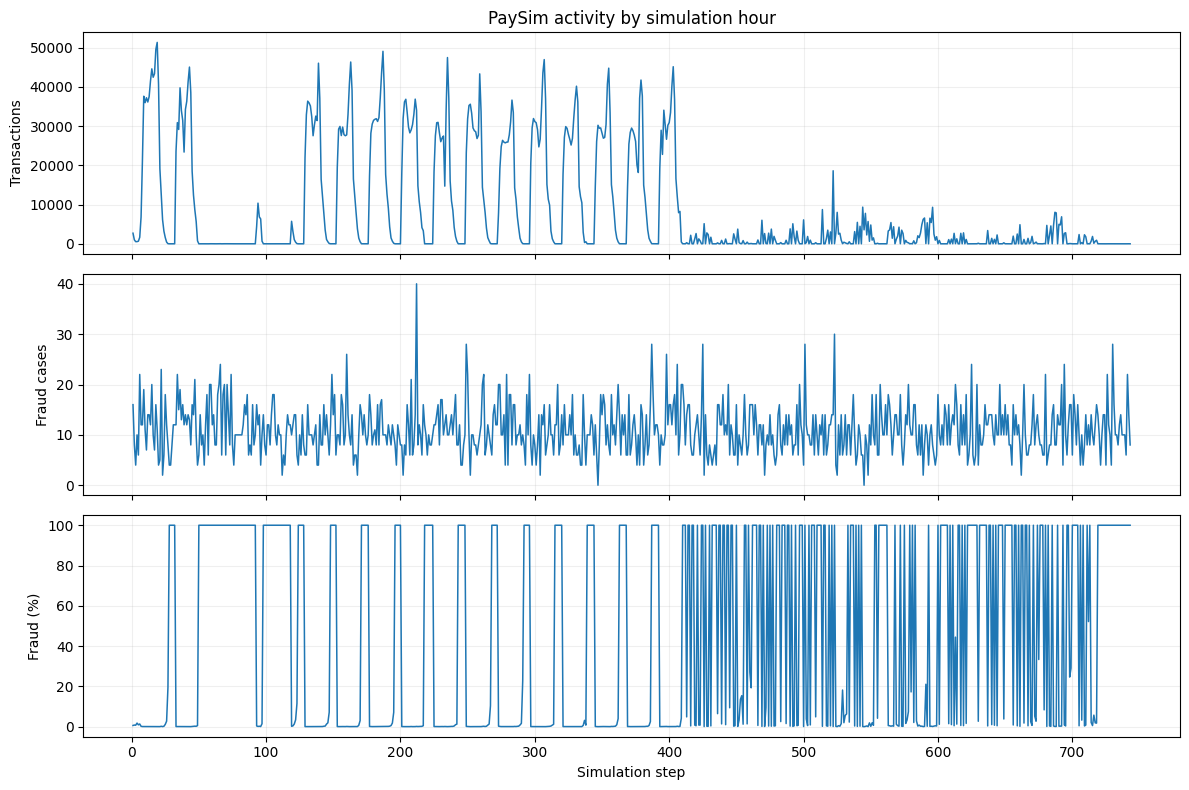

In [42]:
# Transaction and fraud patterns over time
full_steps = pd.RangeIndex(first_step, last_step + 1, name="step")
timeline = by_step.set_index("step").reindex(full_steps, fill_value=0).reset_index()
timeline["fraud_rate_pct"] = 100 * timeline["fraud"] / timeline["transactions"].replace(0, np.nan)
missing_steps = timeline.loc[timeline["transactions"] == 0, "step"].tolist()
save_table(timeline, "transactions_by_step")
print("Missing hours in selected range:", len(missing_steps), "| first examples:", missing_steps[:20])


fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, column, ylabel in zip(axes, ["transactions", "fraud", "fraud_rate_pct"],
                            ["Transactions", "Fraud cases", "Fraud (%)"]):
    ax.plot(timeline["step"], timeline[column], linewidth=1.1)
    ax.set_ylabel(ylabel)
axes[0].set_title("PaySim activity by simulation hour")
axes[-1].set_xlabel("Simulation step")
save_figure("time_patterns")

In [43]:
# Descriptive view: three equal-length periods of the timeline (boundaries do not depend on labels).
period_index = ((timeline["step"] - first_step) * 3 // (last_step - first_step + 1)).clip(0, 2)
timeline["period"] = period_index.map({0: "first third", 1: "middle third", 2: "last third"})
thirds = timeline.groupby("period", sort=False).agg(
    first_step=("step", "min"), last_step=("step", "max"), hours=("step", "count"),
    transactions=("transactions", "sum"), fraud=("fraud", "sum"))
thirds["transactions_per_hour"] = thirds["transactions"] / thirds["hours"]
thirds["fraud_per_hour"] = thirds["fraud"] / thirds["hours"]
thirds["fraud_rate_pct"] = 100 * thirds["fraud"] / thirds["transactions"]
display(thirds)
save_table(thirds.reset_index(), "time_thirds")

,first_step,last_step,hours,transactions,fraud,transactions_per_hour,fraud_per_hour,fraud_rate_pct
period,,,,,,,,
first third,1,248,248,3193229,"2,791.0000","12,875.9234",11.2540,0.0874
middle third,249,496,248,2862428,"2,724.0000","11,542.0484",10.9839,0.0952
last third,497,743,247,306963,"2,698.0000","1,242.7652",10.9231,0.8789


### Section note — time patterns
Compare transactions per hour and fraud cases per hour before explaining a change in fraud rate. A lower number of legitimate transactions can increase the rate without increasing the number of fraud cases. These charts describe the data; they do not establish why the simulator changes. Section 15 checks the pattern at several time scales.

## 5. Repeated senders and receivers

Lifetime repetition is an initial structural check. The table separates the percentage of **accounts** that repeat
from the percentage of **transactions** involving those accounts. The chart groups accounts by transaction count.
Repetition later in the dataset, or in the same hour, does not make history available for an earlier transaction.



,role,unique_accounts,repeating_accounts_pct,transactions_in_repeating_accounts_pct,multi_step_accounts_pct,median_transactions,max_transactions
0,sender,6353307,0.1463,0.2925,0.1456,1.0000,3
1,receiver,2722362,16.8845,64.4375,16.8442,1.0000,113


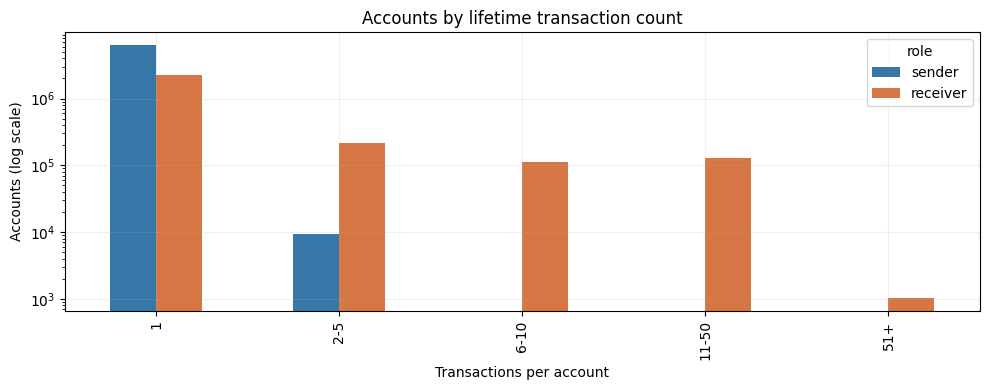

In [44]:
#Repeated senders and receivers
for role, account_column in [("sender", "nameOrig"), ("receiver", "nameDest")]:
    run_sql(f"{role} account profiles", f"""
        CREATE OR REPLACE TEMP TABLE {role}_profile AS
        SELECT {account_column} AS account, COUNT(*) AS transactions,
               COUNT(DISTINCT step) AS active_steps, MIN(step) AS first_step, MAX(step) AS last_step
        FROM paysim GROUP BY {account_column}
    """, fetch=False)

repetition_parts = []
bucket_parts = []
for role in ["sender", "receiver"]:
    repetition_parts.append(run_sql(f"{role} repetition summary", f"""
        SELECT '{role}' AS role, COUNT(*) AS unique_accounts,
               100.0*AVG(CASE WHEN transactions > 1 THEN 1 ELSE 0 END) AS repeating_accounts_pct,
               100.0*SUM(CASE WHEN transactions > 1 THEN transactions ELSE 0 END)/SUM(transactions) AS transactions_in_repeating_accounts_pct,
               100.0*AVG(CASE WHEN active_steps > 1 THEN 1 ELSE 0 END) AS multi_step_accounts_pct,
               MEDIAN(transactions) AS median_transactions, MAX(transactions) AS max_transactions
        FROM {role}_profile
    """))
    bucket_parts.append(run_sql(f"{role} repetition buckets", f"""
        SELECT '{role}' AS role,
               CASE WHEN transactions=1 THEN '1' WHEN transactions<=5 THEN '2-5'
                    WHEN transactions<=10 THEN '6-10' WHEN transactions<=50 THEN '11-50' ELSE '51+' END AS bucket,
               COUNT(*) AS accounts, SUM(transactions) AS transactions
        FROM {role}_profile GROUP BY bucket
    """))
repetition = pd.concat(repetition_parts, ignore_index=True)
buckets = pd.concat(bucket_parts, ignore_index=True)
display(repetition)
save_table(repetition, "account_repetition")
save_table(buckets, "account_repetition_buckets")

order = ["1", "2-5", "6-10", "11-50", "51+"]
bucket_plot = buckets.pivot(index="bucket", columns="role", values="accounts").reindex(index=order, columns=["sender", "receiver"]).fillna(0)
bucket_plot.plot.bar(figsize=(10,4), logy=True, color=["#3677a8", "#d57644"])
plt.title("Accounts by lifetime transaction count")
plt.xlabel("Transactions per account")
plt.ylabel("Accounts (log scale)")
save_figure("account_repetition")

### Section note — repeated accounts
Lifetime repetition is only a first check. The next question is whether an account has appeared before the transaction being scored. Recalculate this for each generator, because a graph-oriented fork may use different account identities and relationships.

## 6. Proposed chronological train / validation / test split

The proposal targets approximately **60% / 20% / 20% of transaction volume**, keeping each hour in one split.
Boundaries depend on time and transaction counts, not labels. Fraud counts describe the resulting imbalance;
they are not a reason to move boundaries until a preferred result appears.

Confirm this protocol before modelling. Fit encoders and scalers on training data only, use validation for choices,
and reserve test data for the final comparison. Full-period charts are exploratory descriptions and must not guide
choices using test labels. Past unlabelled activity may remain available across split boundaries in a sequential evaluation.



In [45]:
#Proposed chronological train / validation / test split
split_boundaries = None
if len(by_step) < 3:
    raise RuntimeError("Fewer than three observed steps: no three-way split possible. Increase MAX_STEP or use the full file.")

cumulative = by_step["transactions"].cumsum().to_numpy()
m = len(by_step)
train_i = int(np.clip(np.searchsorted(cumulative, 0.60*n), 0, m-3))
validation_i = int(np.clip(np.searchsorted(cumulative, 0.80*n), train_i+1, m-2))
train_end = int(by_step.iloc[train_i]["step"])
validation_end = int(by_step.iloc[validation_i]["step"])
split_boundaries = {"train_end_step": train_end, "validation_end_step": validation_end}

SPLIT_NAMES = ["train", "validation", "test"]
SPLIT_SQL = f"CASE WHEN p.step <= {train_end} THEN 'train' WHEN p.step <= {validation_end} THEN 'validation' ELSE 'test' END"
# Row scopes used by the history/coverage tables (column name `step`).
scopes = [("all", "TRUE"),
          ("train", f"step <= {train_end}"),
          ("validation", f"step > {train_end} AND step <= {validation_end}"),
          ("test", f"step > {validation_end}")]

split_audit = run_sql("Chronological split summary", f"""
    SELECT CASE WHEN step <= {train_end} THEN 'train'
                WHEN step <= {validation_end} THEN 'validation' ELSE 'test' END AS split,
           MIN(step) AS first_step, MAX(step) AS last_step, COUNT(DISTINCT step) AS hours,
           COUNT(*) AS transactions, 100.0*COUNT(*)/{n} AS share_pct,
           1.0*COUNT(*)/COUNT(DISTINCT step) AS transactions_per_hour,
           SUM(isFraud) AS fraud,
           100.0*SUM(isFraud)/NULLIF(SUM(SUM(isFraud)) OVER (), 0) AS share_of_all_fraud_pct,
           1.0*SUM(isFraud)/COUNT(DISTINCT step) AS fraud_per_hour,
           100.0*AVG(isFraud) AS fraud_rate_pct
    FROM paysim GROUP BY split ORDER BY first_step
""")
split_audit["fraud_rate_ratio_vs_train"] = split_audit["fraud_rate_pct"] / (float(split_audit.loc[0, "fraud_rate_pct"]) or np.nan)
display(split_audit)
save_table(split_audit, "proposed_time_splits")
assert int(split_audit["transactions"].sum()) == n
assert len(split_audit) == 3
if (split_audit["fraud"] == 0).any():
    print("A split has no fraud. Some metrics will be undefined; discuss the protocol.")

,split,first_step,last_step,hours,transactions,share_pct,transactions_per_hour,fraud,share_of_all_fraud_pct,fraud_per_hour,fraud_rate_pct,fraud_rate_ratio_vs_train
0,train,1,281,281,3820599,60.0476,"13,596.4377","3,193.0000",38.8774,11.3630,0.0836,1.0000
1,validation,282,355,74,1293285,20.3263,"17,476.8243",770.0000,9.3754,10.4054,0.0595,0.7124
2,test,356,743,388,1248736,19.6261,"3,218.3918","4,250.0000",51.7472,10.9536,0.3403,4.0724


In [46]:
# Distribution shift across the split (descriptive; the boundaries above were fixed without labels).
shift = split_audit.set_index("split")
f = lambda s, c: float(shift.loc[s, c])
shift_lines = [
    "Fraud rate: " + " | ".join(f"{s} {f(s, 'fraud_rate_pct'):.4f}%" for s in SPLIT_NAMES)
    + f"  (test is {f('test','fraud_rate_pct')/f('train','fraud_rate_pct'):.1f}x the training rate)",
    f"Share of all fraud cases that fall in the test period: {f('test','share_of_all_fraud_pct'):.1f}%",
    "Transactions per hour: " + " | ".join(f"{s} {f(s, 'transactions_per_hour'):,.0f}" for s in SPLIT_NAMES),
    "Fraud cases per hour: " + " | ".join(f"{s} {f(s, 'fraud_per_hour'):.1f}" for s in SPLIT_NAMES),
]
print("\n".join(shift_lines))

Fraud rate: train 0.0836% | validation 0.0595% | test 0.3403%  (test is 4.1x the training rate)
Share of all fraud cases that fall in the test period: 51.7%
Transactions per hour: train 13,596 | validation 17,477 | test 3,218
Fraud cases per hour: train 11.4 | validation 10.4 | test 11.0


### Section note — the evaluation split
Use the printed split table for this run. Report prevalence beside Average Precision and use the same alert budget for every model. A validation threshold may behave differently later; this is something to measure, not assume. Keep raw step out of the model and fit preprocessing only on training rows. The existing file has already been explored, so its test set is an exploratory holdout rather than a completely untouched confirmatory test.

## 7. History available in the previous 6, 24 and 48 hours

Group by account and hour, then use `LAG(step)` to find the previous **distinct** hour. For a 24-hour window at
hour `t`, history must satisfy `t - 24 <= earlier_step < t`. Two transactions in an account's first hour both have
no prior history. At hour 34, activity at hour 10 is included; at hour 35, it is outside that window.

Coverage means the percentage of **transactions** with at least one qualifying earlier transaction in the same role.
It does not measure a feature's predictive value. The table reports coverage for all rows and **separately for train,
validation and test**, because the three periods have very different volumes per hour (Section 6).
Early observations have less possible history because nothing before the file is known.



scope                    all_pct  train_pct  validation_pct  test_pct
role     window                                                      
receiver any_prior_step  56.4660    56.2042         57.3538   56.3476
         prior_24h       37.0007    44.8917         30.7927   19.2873
         prior_48h       45.9878    51.4340         45.1222   30.2215
         prior_6h        21.3561    28.5686         13.1207    7.8183
sender   any_prior_step   0.1456     0.0887          0.2078    0.2555
         prior_24h        0.0174     0.0171          0.0204    0.0149
         prior_48h        0.0312     0.0305          0.0380    0.0263
         prior_6h         0.0059     0.0063          0.0056    0.0048

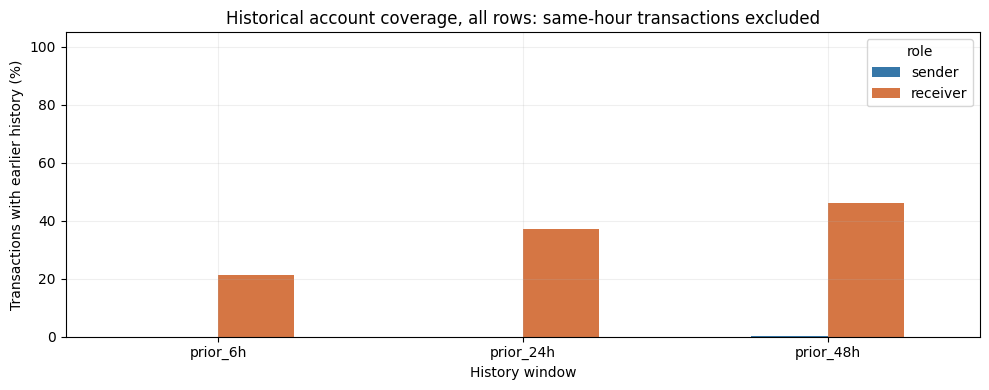

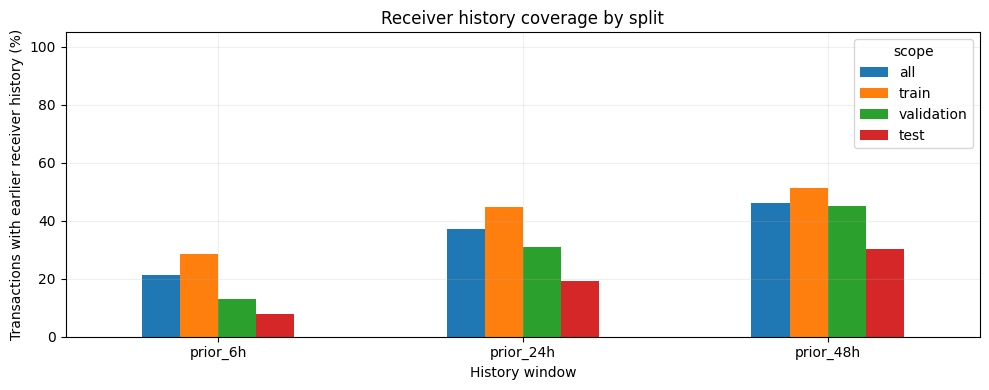

In [47]:
# Labels are deliberately absent from the account-history tables.
for role, account_column in [("sender", "nameOrig"), ("receiver", "nameDest")]:
    run_sql(f"{role} history", f"""
        CREATE OR REPLACE TEMP TABLE {role}_history AS
        WITH activity AS (
            SELECT {account_column} AS account, step, COUNT(*) AS transactions
            FROM paysim GROUP BY {account_column}, step
        )
        SELECT *, LAG(step) OVER (PARTITION BY account ORDER BY step) AS previous_step
        FROM activity
    """, fetch=False)

history_conditions = [("any_prior_step", "previous_step IS NOT NULL")]
history_conditions += [(f"prior_{w}h", f"step - previous_step BETWEEN 1 AND {w}") for w in WINDOWS]
SCOPE_ORDER = [s for s, _ in scopes]

coverage_rows = []
for role in ["sender", "receiver"]:
    window_counts = ", ".join(
        f"SUM(CASE WHEN {condition} THEN transactions ELSE 0 END) AS {window}"
        for window, condition in history_conditions
    )
    for scope, where in scopes:
        counts = con.execute(f"SELECT SUM(transactions), {window_counts} FROM {role}_history WHERE {where}").fetchone()
        denominator = int(counts[0])
        for (window, _), covered in zip(history_conditions, counts[1:]):
            coverage_rows.append({"role": role, "window": window, "scope": scope,
                                  "transactions": denominator, "covered_transactions": int(covered),
                                  "coverage_pct": 100.0 * int(covered) / denominator})
coverage = pd.DataFrame(coverage_rows)
coverage_comparison = (coverage.pivot(index=["role", "window"], columns="scope", values="coverage_pct")
                       [SCOPE_ORDER].add_suffix("_pct"))
display(coverage_comparison)
save_table(coverage, "historical_coverage")

window_order = [f"prior_{w}h" for w in WINDOWS]
coverage[coverage["scope"] == "all"].pivot(index="window", columns="role", values="coverage_pct").reindex(
    index=window_order, columns=["sender", "receiver"]
).plot.bar(figsize=(10, 4), color=["#3677a8", "#d57644"])
plt.ylim(0, 105)
plt.ylabel("Transactions with earlier history (%)")
plt.xlabel("History window")
plt.xticks(rotation=0)
plt.title("Historical account coverage, all rows: same-hour transactions excluded")
save_figure("historical_coverage")

coverage[coverage["role"] == "receiver"].pivot(index="window", columns="scope", values="coverage_pct").reindex(
    index=window_order, columns=SCOPE_ORDER
).plot.bar(figsize=(10, 4))
plt.ylim(0, 105)
plt.ylabel("Transactions with earlier receiver history (%)")
plt.xlabel("History window")
plt.xticks(rotation=0)
plt.title("Receiver history coverage by split")
save_figure("receiver_coverage_by_split")

### Section note — history coverage
Coverage tells me how often a historical feature can be nonzero. It does not prove that it improves detection. Compare sender and receiver coverage across splits. Lower transaction volume is one possible explanation for weaker coverage, but changes in the account population could also matter.

## 7b. Receiver history on the rows that matter: TRANSFER and CASH_OUT

The earlier PaySim audit found fraud in `TRANSFER` and `CASH_OUT`, so coverage computed over all rows may overstate how useful receiver history
is. Repeating receivers are probably dominated by merchants (`M`-prefixed accounts, mostly `PAYMENT` rows), which can never be
fraudulent here. This section recomputes receiver coverage on `TRANSFER`/`CASH_OUT` rows only. The history itself still counts
all earlier incoming transactions, because that is the information a real feature could use. No labels are used.



In [66]:
window_exprs = ", ".join(
    f"100.0*AVG(CASE WHEN h.previous_step IS NOT NULL AND p.step - h.previous_step <= {w} THEN 1 ELSE 0 END) AS prior_{w}h_pct"
    for w in WINDOWS
)
GROUP_SQL = "CASE WHEN p.type IN ('TRANSFER','CASH_OUT') THEN 'TRANSFER/CASH_OUT' ELSE 'other types' END"
join_sql = "FROM paysim p JOIN receiver_history h ON h.account = p.nameDest AND h.step = p.step"

tc_cov = run_sql("Receiver coverage by row group and split", f"""
    SELECT {GROUP_SQL} AS row_group, {SPLIT_SQL} AS split, COUNT(*) AS transactions, {window_exprs}
    {join_sql} GROUP BY 1, 2
""")
tc_cov["split"] = pd.Categorical(tc_cov["split"], SPLIT_NAMES, ordered=True)
tc_cov = tc_cov.sort_values(["row_group", "split"]).reset_index(drop=True)
display(tc_cov)
save_table(tc_cov, "receiver_coverage_tc_vs_other")

prefix_cov = run_sql("Receiver coverage by receiver prefix", f"""
    SELECT {GROUP_SQL} AS row_group, substr(p.nameDest, 1, 1) AS receiver_prefix, {SPLIT_SQL} AS split,
           COUNT(*) AS transactions, {window_exprs}
    {join_sql} GROUP BY 1, 2, 3
""")
prefix_cov["share_of_group_split_pct"] = 100 * prefix_cov["transactions"] / prefix_cov.groupby(["row_group", "split"])["transactions"].transform("sum")
prefix_cov["split"] = pd.Categorical(prefix_cov["split"], SPLIT_NAMES, ordered=True)
prefix_cov = prefix_cov.sort_values(["row_group", "receiver_prefix", "split"]).reset_index(drop=True)
display(prefix_cov)
save_table(prefix_cov, "receiver_coverage_by_prefix")

all_rows_24 = coverage[(coverage["role"] == "receiver") & (coverage["window"] == "prior_24h")].set_index("scope")["coverage_pct"]
tc_lines = []
for s in SPLIT_NAMES:
    tc_val = float(tc_cov[(tc_cov["row_group"] == "TRANSFER/CASH_OUT") & (tc_cov["split"] == s)]["prior_24h_pct"].iloc[0])
    tc_lines.append(f"Receiver prior-24h coverage, {s}: all rows {all_rows_24[s]:.2f}% | TRANSFER/CASH_OUT rows only {tc_val:.4f}%")
print("\n".join(tc_lines))
tc_train_24 = float(tc_cov[(tc_cov["row_group"] == "TRANSFER/CASH_OUT") & (tc_cov["split"] == "train")]["prior_24h_pct"].iloc[0])

,row_group,split,transactions,prior_6h_pct,prior_24h_pct,prior_48h_pct
0,TRANSFER/CASH_OUT,train,1672907,42.9597,67.3703,77.1736
1,TRANSFER/CASH_OUT,validation,565562,19.6424,46.0073,67.3580
2,TRANSFER/CASH_OUT,test,531940,12.0015,29.5103,46.1037
3,other types,train,2147692,17.3590,27.3823,31.3845
4,other types,validation,727723,8.0522,18.9685,27.8414
5,other types,test,716796,4.7139,11.7008,18.4352


,row_group,receiver_prefix,split,transactions,prior_6h_pct,prior_24h_pct,prior_48h_pct,share_of_group_split_pct
0,TRANSFER/CASH_OUT,C,train,1672907,42.9597,67.3703,77.1736,100.0000
1,TRANSFER/CASH_OUT,C,validation,565562,19.6424,46.0073,67.3580,100.0000
2,TRANSFER/CASH_OUT,C,test,531940,12.0015,29.5103,46.1037,100.0000
3,other types,C,train,860533,43.3209,68.3315,78.3138,40.0678
4,other types,C,validation,294474,19.8968,46.8683,68.7881,40.4651
5,other types,C,test,285709,11.8225,29.3484,46.2355,39.8592
6,other types,M,train,1287159,0.0020,0.0056,0.0098,59.9322
7,other types,M,validation,433249,0.0016,0.0053,0.0104,59.5349
8,other types,M,test,431087,0.0026,0.0046,0.0102,60.1408


Receiver prior-24h coverage, train: all rows 44.89% | TRANSFER/CASH_OUT rows only 67.3703%
Receiver prior-24h coverage, validation: all rows 30.79% | TRANSFER/CASH_OUT rows only 46.0073%
Receiver prior-24h coverage, test: all rows 19.29% | TRANSFER/CASH_OUT rows only 29.5103%


## 8. Compact pair and flow feasibility check

A directed pair is a specific sender–receiver combination. Count lifetime pair repetition, then separately check
whether each transaction's pair appeared at an **earlier hour**. For flow, check whether the current sender ever
received a transaction at an earlier hour. Joining the first observed hour is sufficient for these existence checks.

These two historical checks use **any earlier step**, not a 24-hour window. They do not measure money forwarded,
flow amounts or fraudulent intent. Detailed windowed pair and incoming/outgoing features can be investigated later.


In [49]:
run_sql("Pair profiles", """
    CREATE OR REPLACE TEMP TABLE pair_profile AS
    SELECT nameOrig, nameDest, COUNT(*) AS transactions, MIN(step) AS first_step
    FROM paysim GROUP BY nameOrig, nameDest
""", fetch=False)
unique_pairs, repeated_pairs = con.execute("""
    SELECT COUNT(*), COUNT(*) FILTER (WHERE transactions > 1) FROM pair_profile
""").fetchone()
unique_pairs, repeated_pairs = int(unique_pairs), int(repeated_pairs)
rows_sharing_a_pair = n - unique_pairs   # 0 means no two rows share a sender-receiver pair, hence no exact duplicate rows

# First occurrence is used only to ask whether something happened strictly before the current hour.
pair_conditions = [
    f"100.0 * COUNT(*) FILTER (WHERE p.step > q.first_step AND {where}) / NULLIF(COUNT(*) FILTER (WHERE {where}), 0) AS {scope}"
    for scope, where in [(s, w.replace("step", "p.step")) for s, w in scopes]
]
pair_percentages = con.execute(f"""
    SELECT {', '.join(pair_conditions)} FROM paysim p JOIN pair_profile q USING (nameOrig, nameDest)
""").fetchone()
flow_conditions = [
    f"100.0 * SUM(CASE WHEN s.step > r.first_step AND {where} THEN s.transactions ELSE 0 END) / NULLIF(SUM(CASE WHEN {where} THEN s.transactions ELSE 0 END), 0) AS {scope}"
    for scope, where in [(s, w.replace("step", "s.step")) for s, w in scopes]
]
flow_percentages = con.execute(f"""
    SELECT {', '.join(flow_conditions)}
    FROM sender_history s LEFT JOIN receiver_profile r USING (account)
""").fetchone()
pair_coverage = dict(zip(SCOPE_ORDER, map(float, pair_percentages)))
flow_coverage = dict(zip(SCOPE_ORDER, map(float, flow_percentages)))

pad = (np.nan,) * (len(SCOPE_ORDER) - 1)
pair_flow_summary = pd.DataFrame([
    ("Unique directed pairs", "pairs", unique_pairs) + pad,
    ("Pairs occurring more than once (lifetime)", "pairs", repeated_pairs) + pad,
    ("Transaction pair seen at an earlier hour", "% of transactions") + tuple(pair_coverage[s] for s in SCOPE_ORDER),
    ("Sender received a transaction at an earlier hour", "% of transactions") + tuple(flow_coverage[s] for s in SCOPE_ORDER),
], columns=["check", "unit"] + [f"{s}_rows" for s in SCOPE_ORDER])
display(pair_flow_summary)
save_table(pair_flow_summary, "pair_and_flow_feasibility")
print(f"Rows minus unique pairs = {rows_sharing_a_pair:,}: "
      + ("every row has its own sender-receiver pair, so there are no exact duplicate rows." if rows_sharing_a_pair == 0
         else "some rows share a pair; exact duplicates need a separate check."))
_ = con.execute("DROP TABLE pair_profile")

,check,unit,all_rows,train_rows,validation_rows,test_rows
0,Unique directed pairs,pairs,"6,362,620.0000",NaN,NaN,NaN
1,Pairs occurring more than once (lifetime),pairs,0.0000,NaN,NaN,NaN
2,Transaction pair seen at an earlier hour,% of transactions,0.0000,0.0000,0.0000,0.0000
3,Sender received a transaction at an earlier hour,% of transactions,0.0141,0.0094,0.0208,0.0218


Rows minus unique pairs = 0: every row has its own sender-receiver pair, so there are no exact duplicate rows.


### Section note — pairs and flow
If repeated pairs are zero in this run, a repeat-pair feature is constant here. Do not generalise that finding to other generators. The flow flag only says that the sender received money earlier; it does not show that the same money was forwarded or that the behaviour was fraudulent.

## 9. Does history carry any fraud signal? (training rows only)

Coverage tells me where a feature *can* vary, not whether it *helps*. This check uses **training rows only** to compare fraud
rates with and without each history flag. It is a feasibility screen, not model evaluation: validation and test labels are not
used. Because all fraud sits in `TRANSFER`/`CASH_OUT`, the check is repeated on those rows only; otherwise a flag could look
informative merely because it correlates with transaction type.

Flags: `receiver_prior_24h` (the receiver had incoming activity in the previous 24 hours) and `sender_received_earlier`
(the sender received money at an earlier hour, the flow-through idea).



In [50]:
def fraud_by_history_flag(label, row_filter):
    return run_sql(label, f"""
        WITH r AS (SELECT account, step,
                          (previous_step IS NOT NULL AND step - previous_step <= 24) AS flag
                   FROM receiver_history)
        SELECT 'receiver_prior_24h' AS feature, r.flag AS flag, COUNT(*) AS transactions,
               SUM(p.isFraud) AS fraud, 100.0*AVG(p.isFraud) AS fraud_rate_pct
        FROM paysim p JOIN r ON r.account = p.nameDest AND r.step = p.step
        WHERE p.step <= {train_end} AND {row_filter} GROUP BY 1, 2
        UNION ALL
        SELECT 'sender_received_earlier', COALESCE(p.step > f.first_step, FALSE),
               COUNT(*), SUM(p.isFraud), 100.0*AVG(p.isFraud)
        FROM paysim p LEFT JOIN receiver_profile f ON f.account = p.nameOrig
        WHERE p.step <= {train_end} AND {row_filter} GROUP BY 1, 2
    """).sort_values(["feature", "flag"]).reset_index(drop=True)

label_check_all = fraud_by_history_flag("Fraud rate by history flag (train, all rows)", "TRUE")
label_check_tc = fraud_by_history_flag("Fraud rate by history flag (train, TRANSFER/CASH_OUT)", "p.type IN ('TRANSFER','CASH_OUT')")
print("Training rows, all types"); display(label_check_all)
print("Training rows, TRANSFER/CASH_OUT only"); display(label_check_tc)
save_table(label_check_all, "history_flag_fraud_rate_train_all")
save_table(label_check_tc, "history_flag_fraud_rate_train_tc")

def describe_flags(table, scope_label, min_cases=30):
    lines = []
    for feature, g in table.groupby("feature"):
        g = g.set_index("flag")
        if True not in g.index or False not in g.index:
            lines.append(f"[{scope_label}] {feature}: only one flag value occurs in training; no comparison possible.")
            continue
        t, f_ = g.loc[True], g.loc[False]
        ratio = float(t["fraud_rate_pct"]) / float(f_["fraud_rate_pct"]) if float(f_["fraud_rate_pct"]) > 0 else float("nan")
        note = f" (only {int(t['fraud'])} fraud cases with the flag: too few to conclude)" if int(t["fraud"]) < min_cases else ""
        lines.append(f"[{scope_label}] {feature}: fraud rate {float(t['fraud_rate_pct']):.4f}% with flag ({int(t['fraud']):,} of {int(t['transactions']):,}) "
                     f"vs {float(f_['fraud_rate_pct']):.4f}% without ({int(f_['fraud']):,} of {int(f_['transactions']):,}); ratio {ratio:.2f}x{note}")
    return lines

flag_lines = describe_flags(label_check_all, "all types") + describe_flags(label_check_tc, "TRANSFER/CASH_OUT")
print("\n".join(flag_lines))

Training rows, all types


,feature,flag,transactions,fraud,fraud_rate_pct
0,receiver_prior_24h,False,2105469,"2,461.0000",0.1169
1,receiver_prior_24h,True,1715130,732.0000,0.0427
2,sender_received_earlier,False,3820240,"3,193.0000",0.0836
3,sender_received_earlier,True,359,0.0000,0.0000


Training rows, TRANSFER/CASH_OUT only


,feature,flag,transactions,fraud,fraud_rate_pct
0,receiver_prior_24h,False,545864,"2,461.0000",0.4508
1,receiver_prior_24h,True,1127043,732.0000,0.0649
2,sender_received_earlier,False,1672760,"3,193.0000",0.1909
3,sender_received_earlier,True,147,0.0000,0.0000


[all types] receiver_prior_24h: fraud rate 0.0427% with flag (732 of 1,715,130) vs 0.1169% without (2,461 of 2,105,469); ratio 0.37x
[all types] sender_received_earlier: fraud rate 0.0000% with flag (0 of 359) vs 0.0836% without (3,193 of 3,820,240); ratio 0.00x (only 0 fraud cases with the flag: too few to conclude)
[TRANSFER/CASH_OUT] receiver_prior_24h: fraud rate 0.0649% with flag (732 of 1,127,043) vs 0.4508% without (2,461 of 545,864); ratio 0.14x
[TRANSFER/CASH_OUT] sender_received_earlier: fraud rate 0.0000% with flag (0 of 147) vs 0.1909% without (3,193 of 1,672,760); ratio 0.00x (only 0 fraud cases with the flag: too few to conclude)


### Section note — the label screen
A difference in training fraud rates is a reason to test a feature, not evidence of out-of-sample improvement. Small flagged groups can give unstable rates. Keep the model comparison in Section 18 as the main test, including sparse features as a separately reported experiment if needed.

## 10. Preliminary graph-feature plan

The evidence below uses training rows and unlabelled history coverage (Section 9 adds a label screen on training rows).
Coverage is classified with explicit thresholds so the wording is consistent:

| Training coverage | Assessment |
|---|---|
| exactly 0% | constant, drop |
| below 1% | very sparse: defer, at most a cold-start flag |
| 1% to 10% | sparse: optional |
| 10% or more | adequate: build first |

These are **proposed features**, not features already implemented by this audit. Positive coverage justifies checking feature
variation; higher coverage does not prove better detection. Build the transaction-only baseline first, then the receiver-side
historical counts, amounts, unique senders (fan-in) and the **change between adjacent windows**, which is the temporal aspect
my supervisor asked me to keep in mind. Compare under the same chronological protocol before drawing performance conclusions.


In [51]:
# Essential consistency checks remain, without a separate diagnostics report.
for role in ["sender", "receiver"]:
    bad, total = con.execute(f"""
        SELECT COUNT(*) FILTER (WHERE previous_step >= step), SUM(transactions)
        FROM {role}_history
    """).fetchone()
    assert bad == 0 and int(total) == n
assert int(fraud_by_type["transactions"].sum()) == n
assert int(timeline["transactions"].sum()) == n
assert coverage["coverage_pct"].between(0, 100).all()
for _, group in coverage.groupby(["role", "scope"]):
    counts = group.set_index("window")["covered_transactions"]
    ordered = [int(counts[f"prior_{w}h"]) for w in sorted(WINDOWS)] + [int(counts["any_prior_step"])]
    assert all(a <= b for a, b in zip(ordered, ordered[1:]))
for role in ["sender", "receiver"]:   # the three splits must add up to all rows
    parts = coverage[(coverage["role"] == role) & (coverage["window"] == "any_prior_step")].set_index("scope")["transactions"]
    assert int(parts[SPLIT_NAMES].sum()) == int(parts["all"]) == n
assert int(tc_cov["transactions"].sum()) == n
assert all(0 <= x <= 100 for x in list(pair_coverage.values()) + list(flow_coverage.values()))

def get_coverage(role, window="prior_24h", scope="train"):
    chosen = coverage[(coverage["role"] == role) & (coverage["window"] == window) & (coverage["scope"] == scope)]
    return float(chosen["coverage_pct"].iloc[0]) if len(chosen) else np.nan

def coverage_tier(x):
    if pd.isna(x):
        return "Not assessed"
    if x == 0:
        return "Constant (no prior history): drop"
    if x < 1:
        return "Extremely limited and unsupported by observed training fraud: exclude from the primary feature set"
    if x < 10:
        return "Sparse (1-10%): optional"
    return "Adequate (>=10%): build first"

feature_plan = pd.DataFrame([
    ("Receiver count / amount / unique senders (fan-in), all rows", get_coverage("receiver"), "Receiver activity in prior 24h",
     "Build first: windowed counts, amounts, unique senders for 6/24/48h"),
    ("Receiver features, TRANSFER/CASH_OUT rows only", tc_train_24, "Receiver activity in prior 24h on fraud-relevant types",
     "Use this figure to judge usefulness; report per split"),
    ("Change in receiver degree between adjacent windows", np.nan, "Needs history in two adjacent windows (not yet measured)",
     "Build after the window counts: e.g. (0-24h count) vs (24-48h count)"),
    ("Sender count / amount / fan-out", get_coverage("sender"), "Sender activity in prior 24h",
     "Defer; cold-start flag only"),
    ("Counterparty (pair) novelty", pair_coverage["train"], "Same pair at any earlier hour",
     "Exclude from the primary feature set because it has no variation in this dataset"),
    ("Incoming/outgoing flow-through", flow_coverage["train"], "Sender received at any earlier hour",
     "Exclude from the primary feature set; retain only as an optional robustness ablation among flagged rows"),
], columns=["candidate", "training_history_coverage_pct", "coverage_definition", "proposed_action"])
feature_plan["assessment"] = feature_plan["training_history_coverage_pct"].map(coverage_tier)
display(feature_plan)
save_table(feature_plan, "feature_development_plan")
print("Consistency checks passed. Coverage measures feasibility, not model performance.")

,candidate,training_history_coverage_pct,coverage_definition,proposed_action,assessment
0,Receiver count / amount / unique senders (fan-...,44.8917,Receiver activity in prior 24h,"Build first: windowed counts, amounts, unique ...",Adequate (>=10%): build first
1,"Receiver features, TRANSFER/CASH_OUT rows only",67.3703,Receiver activity in prior 24h on fraud-releva...,Use this figure to judge usefulness; report pe...,Adequate (>=10%): build first
2,Change in receiver degree between adjacent win...,NaN,Needs history in two adjacent windows (not yet...,Build after the window counts: e.g. (0-24h cou...,Not assessed
3,Sender count / amount / fan-out,0.0171,Sender activity in prior 24h,Defer; cold-start flag only,Extremely limited and unsupported by observed ...
4,Counterparty (pair) novelty,0.0000,Same pair at any earlier hour,Exclude from the primary feature set because i...,Constant (no prior history): drop
5,Incoming/outgoing flow-through,0.0094,Sender received at any earlier hour,Exclude from the primary feature set; retain o...,Extremely limited and unsupported by observed ...


Consistency checks passed. Coverage measures feasibility, not model performance.


### Section note — provisional feature choices
Keep the generated coverage table as a feasibility summary. The coverage cutoffs are practical screening rules, not statistical evidence. Section 17 builds a compact receiver baseline and a temporal improvement set. The same experiment must be rerun on fork data before deciding that sender or pair features are unhelpful in general.

## 11. What the audit does and does not establish

**Overview:** I now have checks for validity, time patterns, account repetition and historical coverage. The numeric results must come from the current run, rather than values copied from a previous notebook.

The main open questions are whether the volume drop persists in a longer simulation, whether graph-oriented generators change account reuse, and whether graph features help beyond amount and transaction type.

I exclude post-transaction balances and the supplied fraud flag. Pre-transaction balances are also excluded to keep the existing project's conservative baseline; they are not automatically future information. A separate, justified ablation could test them later. Synthetic patterns do not establish real-world detection performance.

## 12. Save the audit summary


In [52]:
summary_lines = [
    f"PaySim week-three audit (v2) | scope: {mode}",
    f"Transactions: {n:,}; fraud: {int(overview.loc[0, 'fraud']):,}; fraud rate: {float(overview.loc[0, 'fraud_rate_pct']):.4f}%.",
    f"Simulation hours: {first_step} to {last_step}; missing steps inside this range: {len(missing_steps)}.",
    f"Unique directed pairs: {unique_pairs:,}; repeated pairs: {repeated_pairs:,}; rows minus unique pairs: {rows_sharing_a_pair:,} (0 = no exact duplicate rows).",
    f"Proposed whole-hour split: train through {train_end}; validation through {validation_end}; test thereafter.",
] + shift_lines + [
    f"Sender / receiver prior-24h coverage, all rows: {get_coverage('sender', scope='all'):.4f}% / {get_coverage('receiver', scope='all'):.4f}%.",
] + tc_lines + [
    f"Earlier-pair / earlier-incoming coverage, all rows: {pair_coverage['all']:.4f}% / {flow_coverage['all']:.4f}%.",
] + flag_lines + [
    "Feature-plan evidence uses training rows; the Section 9 label screen uses training labels only. No models have been trained.",
]
if MAX_STEP is not None:
    summary_lines.insert(1, "PARTIAL TIME PREFIX: rerun with MAX_STEP=None before reporting full-data findings.")
summary_text = "\n".join(summary_lines)
(RESULTS_DIR / "week3_summary.txt").write_text(summary_text, encoding="utf-8")
metadata = {
    "notebook": "02_PaySim_Generators_Graph_Experiments.ipynb", "run_id": run_id, "scope": mode,
    "source_sha256": source_hash, "source_bytes": source_stat_after.st_size,
    "cache_version": CACHE_VERSION, "cache_reused": cache_ok,
    "max_step": MAX_STEP, "history_windows": list(WINDOWS), "split_boundaries": split_boundaries,
    "history_rule": "strictly earlier hourly steps; inclusive lower window boundary",
    "pair_and_flow_rule": "any strictly earlier hour; no rolling-window flow feature calculated",
    "exact_duplicates_checked": "implied: unique directed pairs equal rows" if rows_sharing_a_pair == 0 else "not excluded: some rows share a pair",
    "label_screen": "fraud rate by history flag on training rows only",
    "coverage_thresholds_pct": {"drop": 0, "very_sparse_below": 1, "sparse_below": 10},
    "versions": {"python": platform.python_version(), "duckdb": duckdb.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__},
}
(RESULTS_DIR / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(summary_text)
print("Saved tables, figures and summary:", RESULTS_DIR.relative_to(PROJECT_ROOT))

PaySim week-three audit (v2) | scope: full
Transactions: 6,362,620; fraud: 8,213; fraud rate: 0.1291%.
Simulation hours: 1 to 743; missing steps inside this range: 0.
Unique directed pairs: 6,362,620; repeated pairs: 0; rows minus unique pairs: 0 (0 = no exact duplicate rows).
Proposed whole-hour split: train through 281; validation through 355; test thereafter.
Fraud rate: train 0.0836% | validation 0.0595% | test 0.3403%  (test is 4.1x the training rate)
Share of all fraud cases that fall in the test period: 51.7%
Transactions per hour: train 13,596 | validation 17,477 | test 3,218
Fraud cases per hour: train 11.4 | validation 10.4 | test 11.0
Sender / receiver prior-24h coverage, all rows: 0.0174% / 37.0007%.
Receiver prior-24h coverage, train: all rows 44.89% | TRANSFER/CASH_OUT rows only 67.37%
Receiver prior-24h coverage, validation: all rows 30.79% | TRANSFER/CASH_OUT rows only 46.01%
Receiver prior-24h coverage, test: all rows 19.29% | TRANSFER/CASH_OUT rows only 29.51%
Earlier

## 13. Generators and graph extensions: what was compared

**Overview:** this notebook now contains an initial empirical comparison between the original PaySim CSV and transaction data generated by the graph-oriented `voutilad/PaySim` fork using `paysim-demo`. The projects below serve different roles: a simulator changes generated behaviour, an exporter writes its output, and a graph-query extension provides a way to store/query relationships. They must not be counted as separate generators simply because their names differ.

### 13.1 Project selection and actual status

| Project or tool | Role | Status in this notebook |
|---|---|---|
| [Original PaySim](https://github.com/EdgarLopezPhD/PaySim) | Reference mobile-money simulator/dataset | The existing public CSV is analysed as `paysim_reference`. It was not regenerated for a controlled matched-seed comparison. |
| [voutilad/PaySim](https://github.com/voutilad/PaySim) | Modified PaySim with first-/third-party fraud and additional client identity information | A generated transaction export is analysed as `paysim_fork_seed123456`. The initial temporal, structural and feature-set comparisons have run. |
| [voutilad/paysim-demo](https://github.com/voutilad/paysim-demo) | Application that runs the fork and exports data | Used to generate transactions, clients and merchants. It is the export route for the fork, not a third generator. |


The fork and demo repositories are archived. Their documentation is useful for identifying intended changes, but it is not a completed source-code diff or evidence that every documented capability was evaluated in this notebook.


The saved outputs show more reusable account/pair structure in the fork. In this execution, the combined basic graph feature set improves overall test Average Precision over transaction-only in both datasets, more strongly in the fork. The expanded combined set is not the overall winner; the fork's TRANSFER/CASH_OUT subgroup is an exception where it outperforms the combined basic set. These are exploratory single-run observations, not evidence that one generator is universally better or that a particular code change caused the differences.



In [53]:
import pandas as pd

fork_path = (
    r"C:\Windows\System32\paysim-demo"
    r"\transactions_with_step.csv.gz"
)

sample = pd.read_csv(fork_path, nrows=5)

print("Columns:", sample.columns.tolist())
print(sample.to_string(index=False))

Columns: ['STEP', 'ACTION', 'AMOUNT', 'IDORIG', 'IDDEST', 'ISFRAUD']
 STEP   ACTION      AMOUNT           IDORIG           IDDEST  ISFRAUD
    0  PAYMENT    535.2728 4634219748903517       74-0007183        1
    0 TRANSFER 39,319.1225 4634219748903517 4665794094572902        1
    0  PAYMENT    534.7321 4281971077744542       88-0003853        1
    0 TRANSFER 41,940.3994 4281971077744542 4368718418491895        1
    0  PAYMENT    602.8361 4241535520267424       55-0001574        1


## 14. Register each run and validate a common transaction view

**Overview:** the shared audit needs six fields: time, type, amount, sender, receiver and transaction label. Each adapter explicitly maps exported columns to these fields. It does not infer labels from node names or silently fill missing information.



In [54]:
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# Additional dataset: my generated PaySim fork

EXTRA_RUNS = [
    {
        "name": "paysim_fork_seed123456",

        "path": (
            r"C:\Windows\System32\paysim-demo"
            r"\transactions_with_step.csv.gz"
        ),

        "generator": "voutilad/PaySim via paysim-demo",
        "commit": None,
        "seed": 123456,
        "configured_hours": None,

        # Assumption: one simulation step represents one hour.
      
        "hours_per_step": 1.0,
        "time_unit_status": "Assumed; requires verification",

        "label_meaning": (
            "Fork transaction ISFRAUD label: 0=no, 1=yes"
        ),

        "config_path": (
            r"C:\Windows\System32\paysim-demo"
            r"\PaySim.properties"
        ),

        "columns": {
            "step": "STEP",
            "type": "ACTION",
            "amount": "AMOUNT",
            "nameOrig": "IDORIG",
            "nameDest": "IDDEST",
            "isFraud": "ISFRAUD"
        }
    }
]




RUNS = [
    {
        "name": "paysim_reference",
        "table": "paysim",
        "generator": "Original PaySim CSV",
        "seed": None,
        "commit": None,
        "configured_hours": None,
        "hours_per_step": 1.0,
        "source_sha256": source_hash,
        "label_meaning": "Original PaySim transaction fraud",
        "path": str(DATA_PATH)
    }
]


# Load and validate an additional dataset


def load_run(spec, index):
    p = Path(spec["path"]).expanduser().resolve()

    if not p.is_file():
        raise FileNotFoundError(
            f"Dataset not found:\n{p}\n"
            "Update the path in EXTRA_RUNS."
        )

    mapping = spec["columns"]

    required = {
        "step",
        "type",
        "amount",
        "nameOrig",
        "nameDest",
        "isFraud"
    }

    if set(mapping) != required:
        raise ValueError(
            "Map exactly the six canonical fields."
        )

    scale = float(spec["hours_per_step"])

    if not np.isfinite(scale) or scale <= 0:
        raise ValueError(
            "hours_per_step must be finite and positive."
        )

    table = f"run_{index}"

    # DuckDB automatically reads the .csv.gz file.

    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW adapter_raw AS
        SELECT *
        FROM read_csv(
            {sql_text(p)},
            header=true,
            all_varchar=true
        )
    """)

    available = set(
        con.execute("DESCRIBE adapter_raw").df().column_name
    )

    missing = set(mapping.values()) - available

    if missing:
        raise ValueError(
            f"Missing source columns: {sorted(missing)}\n"
            f"Available columns: {sorted(available)}"
        )

    selections = []

    for target, original in mapping.items():
        expr = sql_name(original)

        if target == "step":
            expr = f"TRY_CAST({expr} AS DOUBLE) * {scale}"

        elif target in ("amount", "isFraud"):
            expr = f"TRY_CAST({expr} AS DOUBLE)"

        selections.append(
            f"{expr} AS {sql_name(target)}"
        )

    con.execute(f"""
        CREATE OR REPLACE TEMP VIEW adapter_typed AS
        SELECT {", ".join(selections)}
        FROM adapter_raw
    """)

    bad = con.execute("""
        SELECT COUNT(*)
        FROM adapter_typed
        WHERE
            step IS NULL
            OR NOT isfinite(step)
            OR step < 0

            OR amount IS NULL
            OR NOT isfinite(amount)
            OR amount < 0

            OR isFraud IS NULL
            OR NOT isfinite(isFraud)
            OR isFraud NOT IN (0, 1)

            OR nameOrig IS NULL
            OR length(trim(nameOrig)) = 0

            OR nameDest IS NULL
            OR length(trim(nameDest)) = 0

            OR type IS NULL
            OR length(trim(type)) = 0
    """).fetchone()[0]

    if bad:
        raise ValueError(
            f"{spec['name']}: {bad:,} invalid rows. "
            "Check the adapter/source. No rows were dropped."
        )

    con.execute(f"""
        CREATE OR REPLACE TEMP TABLE {table} AS
        SELECT
            step,
            type,
            amount,
            nameOrig,
            nameDest,
            CAST(isFraud AS INTEGER) AS isFraud
        FROM adapter_typed
    """)

    row_count = con.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    if row_count == 0:
        raise ValueError(
            f"{spec['name']}: dataset is empty."
        )

    print(
        f"Loaded {spec['name']}: "
        f"{row_count:,} transactions"
    )

    return {
        **spec,
        "path": str(p),
        "table": table,
        "source_sha256": sha256_file(p)
    }


# Register the additional dataset


names = (
    [r["name"] for r in EXTRA_RUNS]
    + [RUNS[0]["name"]]
)

if len(set(names)) != len(names):
    raise ValueError("Run names must be unique.")

for j, spec in enumerate(EXTRA_RUNS):
    RUNS.append(load_run(spec, j))



# Save and display the registered runs


RESULTS_DIR.mkdir(parents=True, exist_ok=True)

(RESULTS_DIR / "experiment_manifest.json").write_text(
    json.dumps(RUNS, indent=2),
    encoding="utf-8"
)

display(
    
    pd.DataFrame(RUNS).drop(
        columns=["columns"],
        errors="ignore"
    )
)

print("Additional datasets loaded:", len(RUNS) - 1)
print("Registered runs:", [r["name"] for r in RUNS])

print(
    "\nTime-unit caution: the fork is currently configured "
    "as one hour per simulation step. Verify this before "
    "interpreting time-based comparisons."
)

Loaded paysim_fork_seed123456: 1,843,628 transactions


,name,table,generator,seed,commit,configured_hours,hours_per_step,source_sha256,label_meaning,path,time_unit_status,config_path
0,paysim_reference,paysim,Original PaySim CSV,NaN,None,None,1.0000,16910f90577b0d981bf8ff289714510bb89bc71bff7d3f...,Original PaySim transaction fraud,D:\paysim dataset.csv,NaN,NaN
1,paysim_fork_seed123456,run_0,voutilad/PaySim via paysim-demo,"123,456.0000",None,None,1.0000,58a307ce4a61ee3cffb0197983790117b788b7a5869882...,"Fork transaction ISFRAUD label: 0=no, 1=yes",C:\Windows\System32\paysim-demo\transactions_w...,Assumed; requires verification,C:\Windows\System32\paysim-demo\PaySim.properties


Additional datasets loaded: 1
Registered runs: ['paysim_reference', 'paysim_fork_seed123456']

Time-unit caution: the fork is currently configured as one hour per simulation step. Verify this before interpreting time-based comparisons.


### Section note — comparable inputs
A common schema makes the calculations repeatable. It does not make fraud and money laundering the same task. Within each run, compare feature sets on identical rows. Across generators, discuss the direction and consistency of the benefit alongside their structural differences.

## 15. Does the drop persist over longer intervals?

**Overview:** there are two different tests: aggregate the existing file into larger bins, and generate genuinely longer data. Changing a 24-hour history window to 168 hours does not lengthen the simulation. Repeating the CSV also does not create a longer simulation.

Start with 720, 1,440 and 2,160 hours (30/60/90 days), with seeds 11, 42 and 73, while keeping population and fraud parameters fixed. Before running, verify that each simulator can read valid input profiles over the full horizon. If profiles must be extended, describe the policy and label the result as a modified-generator experiment. Keep a same-seed prefix check: a longer run may change the earlier trajectory too.

The code includes hours with zero transactions inside the observed range, calculates daily/weekly bins, and finds the largest decrease between adjacent seven-day mean volumes. This is an exploratory diagnostic, not a statistical change-point test. It reports both absolute time and position within the observed run. Compare positions across seeds and horizons, then inspect simulator input schedules before proposing a cause. A final partial week is retained and marked; its hourly rate uses only observed hours.

No new long-run exports registered; existing reference/fork comparison only.


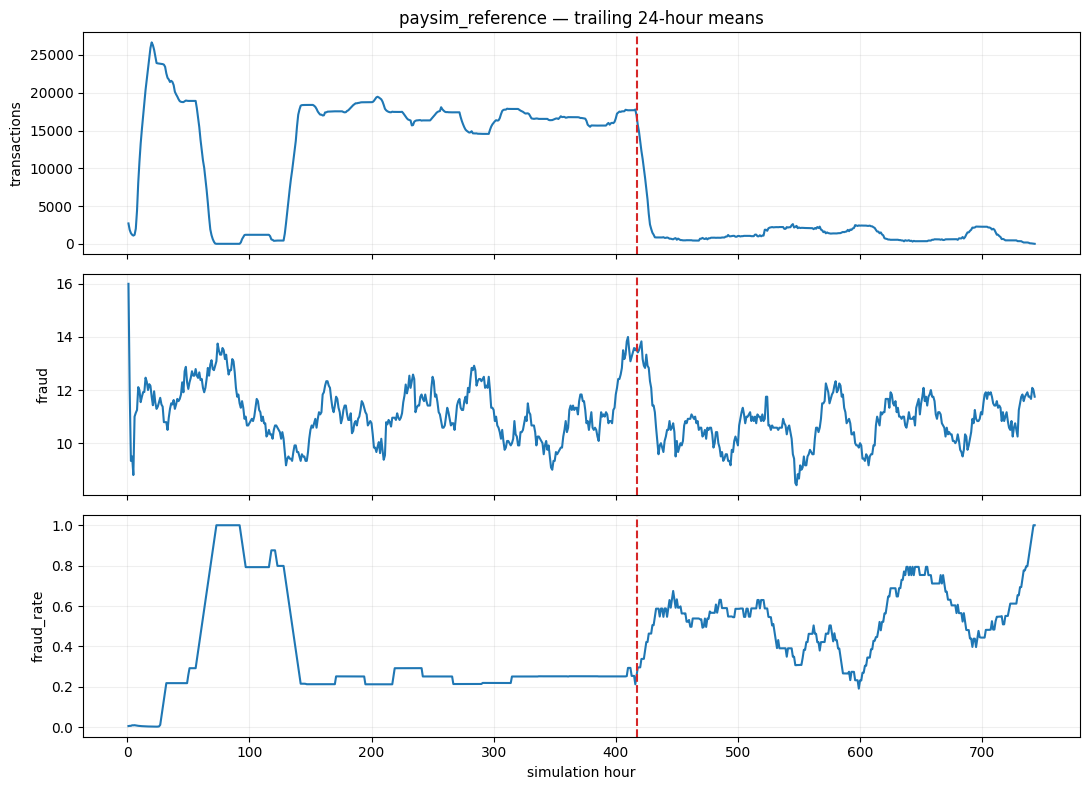

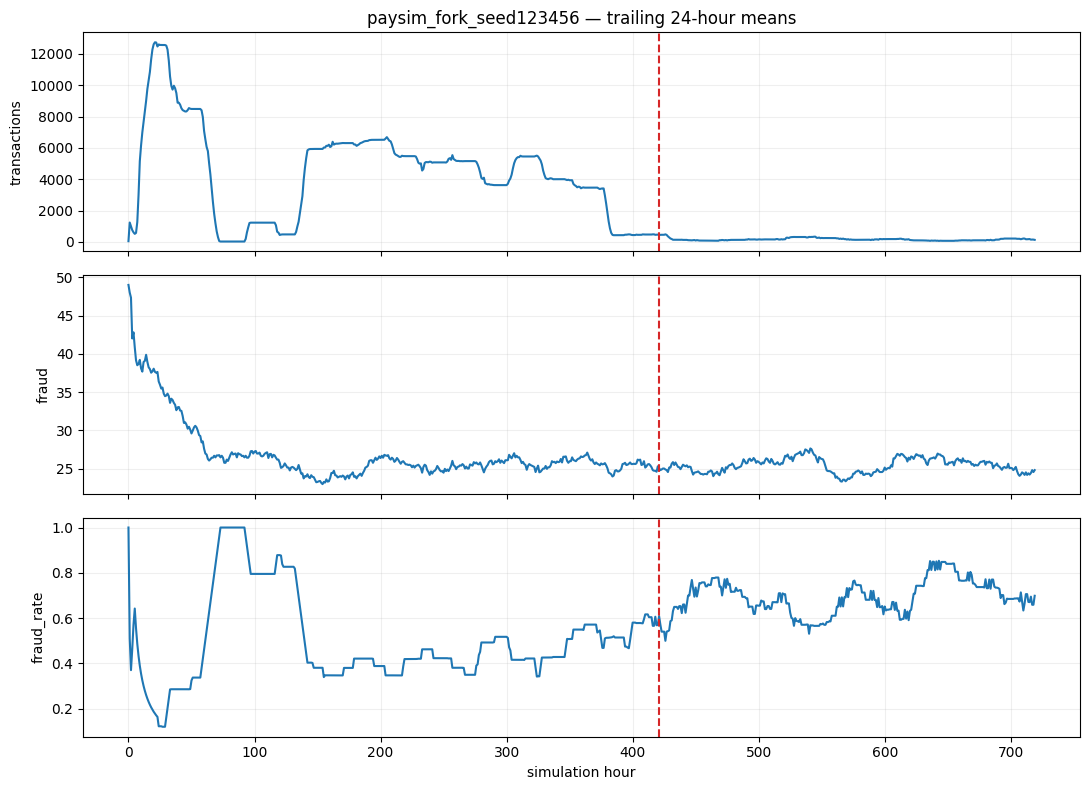

,run,observed_hours,configured_hours,candidate_drop_hour,relative_position,adjacent_week_change
0,paysim_reference,743,None,417,0.5606,-0.9240
1,paysim_fork_seed123456,720,None,421,0.5855,-0.9478


,transactions,fraud,hours,start_hour,bin_hours,partial_bin,transactions_per_hour,fraud_per_hour,fraud_rate,run
0,574255,271.0000,24,1,24,False,"23,927.2917",11.2917,0.0005,paysim_reference
1,455238,309.0000,24,25,24,False,"18,968.2500",12.8750,0.0007,paysim_reference
2,1070,310.0000,24,49,24,False,44.5833,12.9167,0.2897,paysim_reference
3,28240,262.0000,24,73,24,False,"1,176.6667",10.9167,0.0093,paysim_reference
4,9789,252.0000,24,97,24,False,407.8750,10.5000,0.0257,paysim_reference
5,441005,228.0000,24,121,24,False,"18,375.2083",9.5000,0.0005,paysim_reference
6,420583,272.0000,24,145,24,False,"17,524.2917",11.3333,0.0006,paysim_reference
7,449637,278.0000,24,169,24,False,"18,734.8750",11.5833,0.0006,paysim_reference
8,417919,255.0000,24,193,24,False,"17,413.2917",10.6250,0.0006,paysim_reference
9,392945,282.0000,24,217,24,False,"16,372.7083",11.7500,0.0007,paysim_reference


In [55]:
# Register genuine longer generator exports here AFTER validating their profiles and time units.
# A longer CSV must contain newly generated hours; do not concatenate or relabel an old CSV.
# Use the canonical field mapping shown in Section 14 for each export.

LONG_RUN_SPECS = []
if LONG_RUN_SPECS:
    existing_names = {r["name"] for r in RUNS}
    if len({s["name"] for s in LONG_RUN_SPECS}) != len(LONG_RUN_SPECS):
        raise ValueError("Long-run names must be unique")
    for j, spec in enumerate(LONG_RUN_SPECS, start=len(RUNS)):
        if spec["name"] in existing_names:
            raise ValueError(f"Duplicate run name: {spec['name']}")
        if spec.get("configured_hours") is None:
            raise ValueError(f"{spec['name']}: record the configured duration")
        RUNS.append(load_run(spec, j))
        existing_names.add(spec["name"])
    (RESULTS_DIR / "experiment_manifest.json").write_text(
        json.dumps(RUNS, indent=2), encoding="utf-8")
else:
    print("No new long-run exports registered; existing reference/fork comparison only.")

long_run_plan = pd.DataFrame([
    {"generator": g, "hours": h, "seed": s, "status": "pending valid profiles and generation"}
    for g in ["original PaySim", "voutilad/PaySim"]
    for h in [720, 1440, 2160] for s in [11, 42, 73]
])
save_table(long_run_plan, "long_run_plan")

def temporal_audit(run):
    t = run["table"]
    hourly = con.execute(f"""SELECT CAST(floor(step) AS BIGINT) AS "hour",
        count(*) transactions, sum(isFraud) fraud, sum(amount) amount
        FROM {t} GROUP BY 1 ORDER BY 1""").df().set_index("hour")
    lo, hi = int(hourly.index.min()), int(hourly.index.max())
    hourly = hourly.reindex(range(lo, hi+1), fill_value=0)
    hourly.index.name = "hour"
    hourly["fraud_rate"] = hourly.fraud / hourly.transactions.replace(0, np.nan)
    hourly["run"] = run["name"]
    bins = []
    for width in [24, 168]:
        b = hourly.groupby((hourly.index-lo)//width).agg(
            transactions=("transactions", "sum"), fraud=("fraud", "sum"), hours=("transactions", "size"))
        b["start_hour"] = lo + b.index * width
        b["bin_hours"] = width
        b["partial_bin"] = b.hours < width
        b["transactions_per_hour"] = b.transactions / b.hours
        b["fraud_per_hour"] = b.fraud / b.hours
        b["fraud_rate"] = b.fraud / b.transactions.replace(0, np.nan)
        b["run"] = run["name"]
        bins.append(b.reset_index(drop=True))
    # Left block ends at t-1; right block starts at t. Both must have 168 hours.
    left = hourly.transactions.rolling(168, min_periods=168).mean().shift(1)
    right = hourly.transactions.iloc[::-1].rolling(168, min_periods=168).mean().iloc[::-1]
    change = (right-left) / left.replace(0, np.nan)
    valid = change.dropna()
    cut = int(valid.idxmin()) if len(valid) else None
    record = {"run": run["name"], "observed_hours": hi-lo+1,
              "configured_hours": run.get("configured_hours"),
              "candidate_drop_hour": cut,
              "relative_position": (cut-lo)/max(hi-lo, 1) if cut is not None else np.nan,
              "adjacent_week_change": float(valid.min()) if len(valid) else np.nan}
    fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for axis, col in zip(ax, ["transactions", "fraud", "fraud_rate"]):
        axis.plot(hourly.index, hourly[col].rolling(24, min_periods=1).mean())
        axis.set_ylabel(col)
        if cut is not None: axis.axvline(cut, color="tab:red", linestyle="--")
    ax[0].set_title(run["name"] + " — trailing 24-hour means")
    ax[-1].set_xlabel("simulation hour")
    save_figure(f"temporal_run_{RUNS.index(run)}")
    return hourly.reset_index(), pd.concat(bins, ignore_index=True), record

temporal_results = [temporal_audit(r) for r in RUNS]
all_hourly = pd.concat([x[0] for x in temporal_results], ignore_index=True)
all_bins = pd.concat([x[1] for x in temporal_results], ignore_index=True)
drop_candidates = pd.DataFrame([x[2] for x in temporal_results])
for name, frame in [("all_run_hourly", all_hourly), ("all_run_time_bins", all_bins), ("drop_candidates", drop_candidates)]:
    save_table(frame, name)
display(drop_candidates)
display(all_bins.head(12))

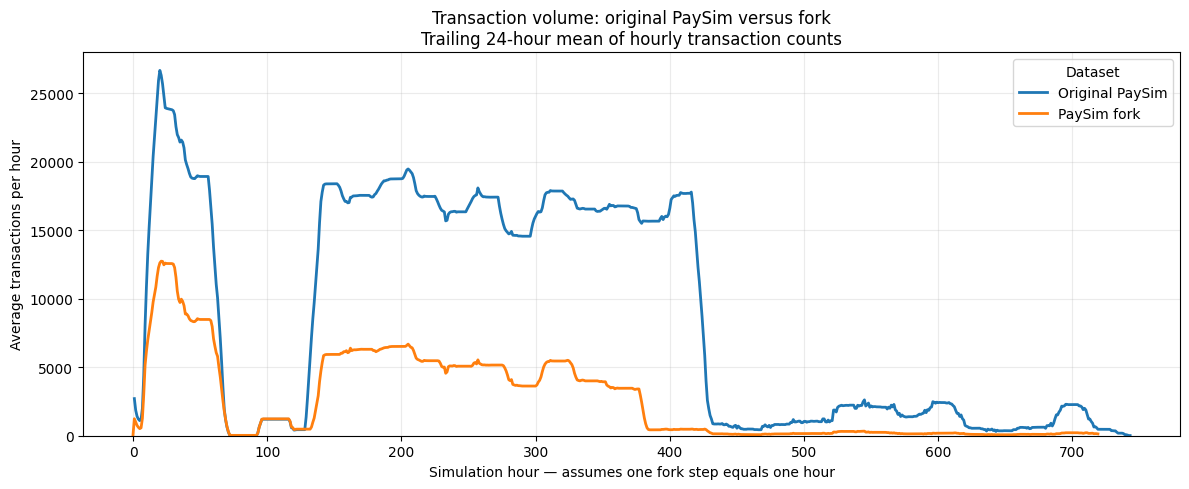

In [56]:
# SECTION 15 — Direct transaction-volume comparison


if "all_hourly" not in globals():
    raise RuntimeError(
        "Run the existing Section 15 code first. "
        "It creates the all_hourly table."
    )

run_labels = {
    "paysim_reference": "Original PaySim",
    "paysim_fork_seed123456": "PaySim fork"
}

run_colors = {
    "paysim_reference": "tab:blue",
    "paysim_fork_seed123456": "tab:orange"
}

fig, ax = plt.subplots(figsize=(12, 5))

for run in RUNS:
    run_name = run["name"]

    # Select this dataset and keep simulation hours in order.
    hourly_run = (
        all_hourly.loc[all_hourly["run"] == run_name]
        .sort_values("hour")
        .copy()
    )

    if hourly_run.empty:
        raise ValueError(f"No hourly results found for {run_name}.")

    # Section 15 includes zero-transaction hours inside each run,
    # so 24 rows represent 24 consecutive hourly bins.
    hourly_run["volume_24h_mean"] = (
        hourly_run["transactions"]
        .rolling(window=24, min_periods=1)
        .mean()
    )

    ax.plot(
        hourly_run["hour"],
        hourly_run["volume_24h_mean"],
        label=run_labels.get(run_name, run_name),
        color=run_colors.get(run_name),
        linewidth=2
    )

ax.set_title(
    "Transaction volume: original PaySim versus fork\n"
    "Trailing 24-hour mean of hourly transaction counts"
)

ax.set_xlabel(
    "Simulation hour — assumes one fork step equals one hour"
)

ax.set_ylabel("Average transactions per hour")
ax.set_ylim(bottom=0)

ax.legend(title="Dataset")
ax.grid(True, alpha=0.25)

# Uses the notebook's existing helper to save and display the figure.
save_figure("original_vs_fork_transaction_volume")

### 15a. Pinpoint the two drops with raw hourly counts

The trailing 24-hour mean in the overview spreads an abrupt change over the following hours. The panels below use **unsmoothed, zero-filled hourly counts** for the two intervals visible in the reference plot: approximately 40–150 and 390–470. They show transaction totals, legitimate transactions, fraud counts and transaction types for each run. The fork's step-to-hour conversion remains an assumption until its local profile is verified.

The fixed windows make before/low/recovery comparisons reproducible: early **24–47, 80–103, 145–168** and late **390–413, 445–468, 500–523**. They describe two distinct changes: a temporary early trough and a later low-volume regime. They are visual diagnostic windows, not boundaries chosen to maximize an effect or proof of a cause. Counts are reported **per hour** because windows can be partially outside a shorter run.

PaySim's original paper says the simulator takes transaction counts by day/hour from an aggregated input and schedules future activity for clients. Its authors noted higher activity in the first 14 days and suggested early-month income as a possible broad explanation. That paper's plotted run is different from this public CSV; it does not identify either of these exact boundaries or prove that they are intended generator features. [Original paper, sections 4–5](https://www.msc-les.org/proceedings/emss/2016/EMSS2016_249.pdf).

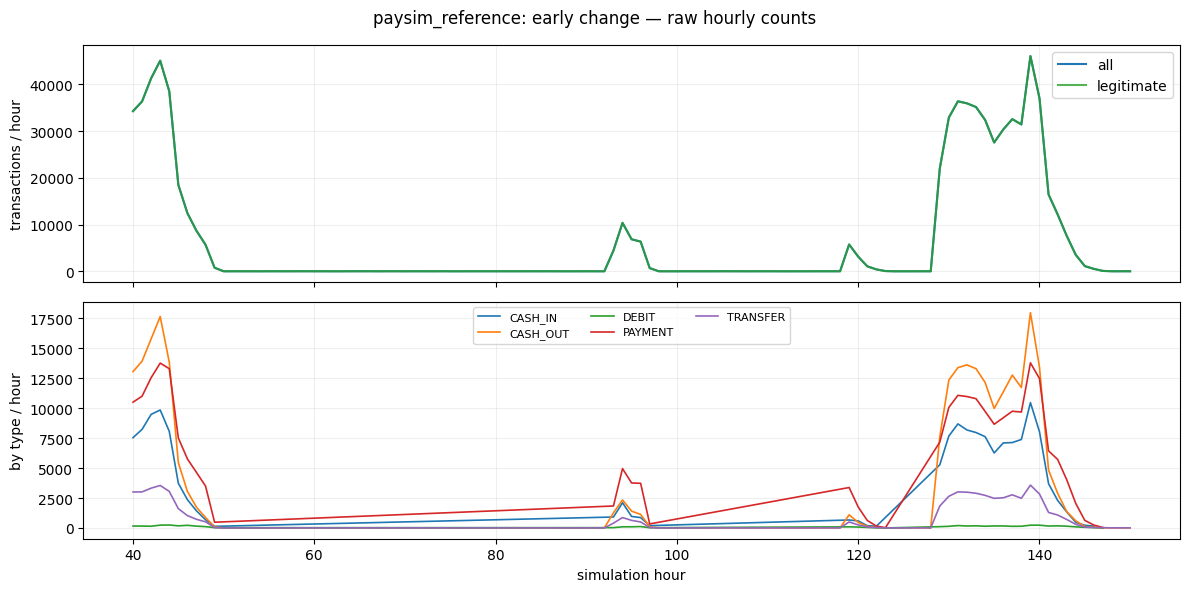

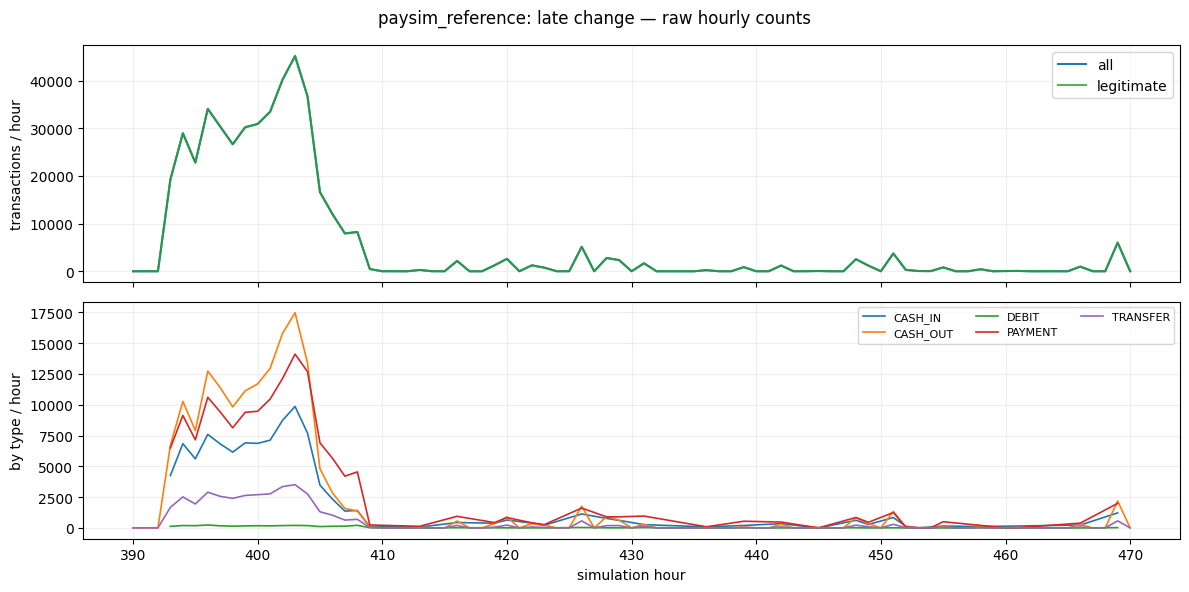

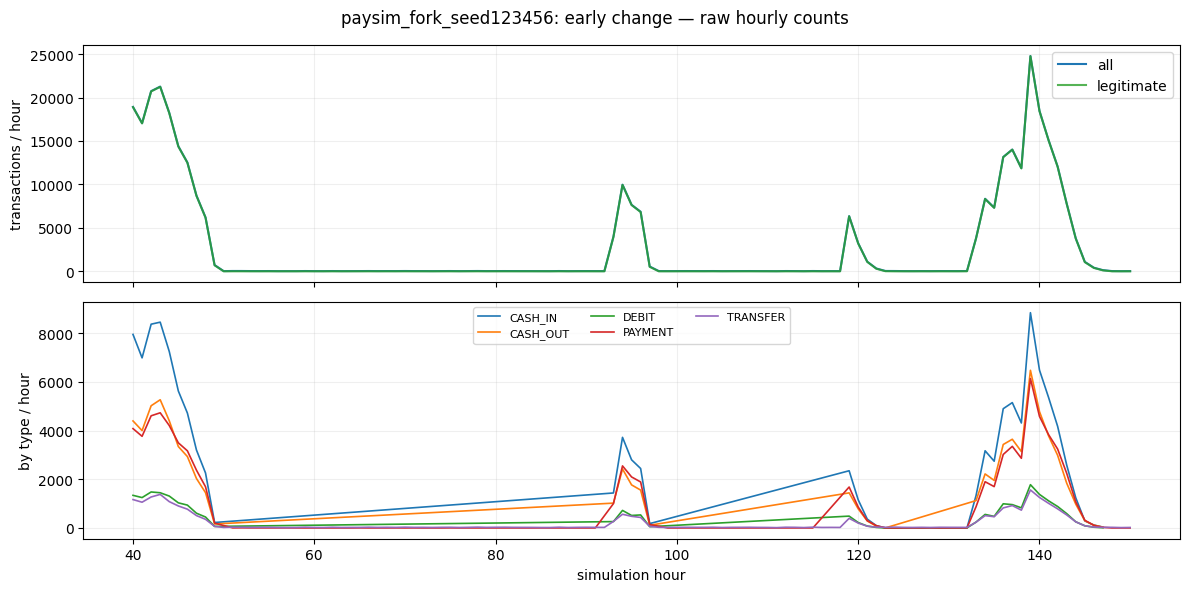

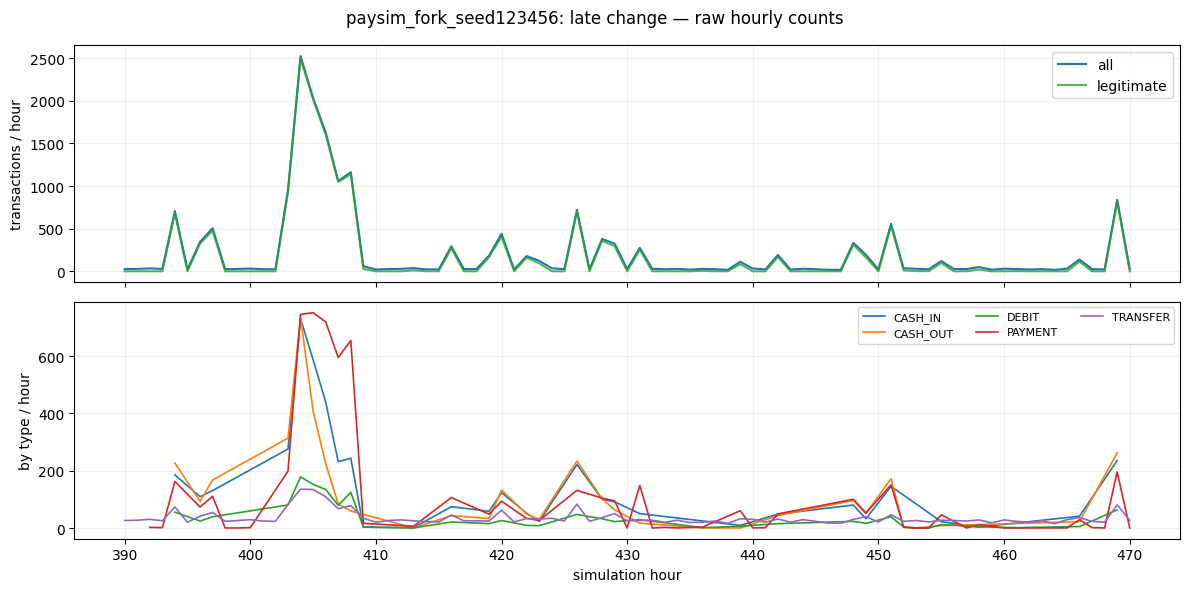

,run,event,period,start,end,hours,transactions_per_hour,legitimate_per_hour,fraud_per_hour
0,paysim_reference,early,before,24,47,24,"18,865.0417","18,852.3333",12.7083
1,paysim_reference,early,low,80,103,24,"1,204.7083","1,193.8750",10.8333
2,paysim_reference,early,recovery,145,168,24,"17,524.2917","17,512.9583",11.3333
3,paysim_reference,late,before,390,413,24,"17,686.4167","17,673.1667",13.2500
4,paysim_reference,late,low,445,468,24,437.6250,427.1250,10.5000
5,paysim_reference,late,later,500,523,24,"1,874.2917","1,862.5417",11.7500
6,paysim_fork_seed123456,early,before,24,47,24,"8,411.5000","8,381.2917",30.2083
7,paysim_fork_seed123456,early,low,80,103,24,"1,229.8333","1,202.8750",26.9583
8,paysim_fork_seed123456,early,recovery,145,168,24,"6,291.6250","6,267.6250",24.0000
9,paysim_fork_seed123456,late,before,390,413,24,473.5417,447.9583,25.5833


period                                    before    later      low   recovery
run                    event type                                            
paysim_fork_seed123456 early CASH_IN  3,460.5833      NaN 440.6667 2,202.4583
                             CASH_OUT 1,965.6667      NaN 286.5417 1,632.8750
                             DEBIT      591.9167      NaN  86.9167   445.3333
                             PAYMENT  1,875.5833      NaN 320.5000 1,574.2500
                             TRANSFER   517.7500      NaN  95.2083   436.7083
                       late  CASH_IN    122.5833  71.3750  13.7083        NaN
                             CASH_OUT    96.5417  74.9167  14.8750        NaN
                             DEBIT       36.6250  19.4167   4.7083        NaN
                             PAYMENT    168.5000  63.5417  17.0000        NaN
                             TRANSFER    49.2917  41.3333  26.1667        NaN
paysim_reference       early CASH_IN  4,146.3333      NaN 210.0833 3,905.6250
                             CASH_OUT 6,846.7917      NaN 264.1250 6,305.7500
                             DEBIT      103.7083      NaN  15.0833   105.7917
                             PAYMENT  6,182.1667      NaN 609.3750 5,760.4167
                             TRANSFER 1,586.0417      NaN 106.0417 1,446.7083
                       late  CASH_IN  3,884.9167 422.0833 100.5000        NaN
                             CASH_OUT 6,334.0417 630.9167 134.0000        NaN
                             DEBIT      117.6250  12.5417   2.9167        NaN
                             PAYMENT  5,869.0000 637.0417 159.3333        NaN
                             TRANSFER 1,480.8333 171.7083  40.8750        NaN

Interpretation: if legitimate types fall together, investigate their shared input schedule or generator state. A temporary early trough and persistent later decline need separate explanations.


In [57]:
# Aggregate transaction types once per run; queries return only hourly summaries.
type_frames = []
for run in RUNS:
    t = sql_name(run["table"])
    frame = con.execute(f"""
        SELECT CAST(floor(step) AS BIGINT) AS hour, type,
               COUNT(*) AS transactions,
               SUM(CASE WHEN isFraud = 0 THEN 1 ELSE 0 END) AS legitimate,
               SUM(isFraud) AS fraud
        FROM {t}
        GROUP BY 1, 2 ORDER BY 1, 2
    """).df()
    frame.insert(0, "run", run["name"])
    type_frames.append(frame)
hourly_types = pd.concat(type_frames, ignore_index=True)
save_table(hourly_types, "hourly_types_drop_audit")

audit_ranges = {"early": (40, 150), "late": (390, 470)}
audit_windows = {
    "early": {"before": (24,47), "low": (80,103), "recovery": (145,168)},
    "late": {"before": (390,413), "low": (445,468), "later": (500,523)}
}
window_rows, type_window_rows = [], []
for run in RUNS:
    label = run["name"]
    h = all_hourly.loc[all_hourly.run == label].sort_values("hour").copy()
    h["legitimate"] = h["transactions"] - h["fraud"]
    t = hourly_types.loc[hourly_types.run == label]
    for event, (start,end) in audit_ranges.items():
        view = h.loc[h.hour.between(start,end)]
        if view.empty: continue
        fig, axes = plt.subplots(2,1,figsize=(12,6),sharex=True)
        axes[0].plot(view.hour,view.transactions,label="all",color="tab:blue")
        axes[0].plot(view.hour,view.legitimate,label="legitimate",color="tab:green",alpha=.8)
        axes[0].set_ylabel("transactions / hour"); axes[0].legend()
        type_view = t.loc[t.hour.between(start,end)]
        for tx_type, part in type_view.groupby("type"):
            axes[1].plot(part.hour,part.transactions,label=str(tx_type),linewidth=1.2)
        axes[1].set_ylabel("by type / hour"); axes[1].set_xlabel("simulation hour")
        axes[1].legend(ncol=3,fontsize=8)
        fig.suptitle(f"{label}: {event} change — raw hourly counts")
        save_figure(f"drop_raw_{label}_{event}")
        for period, (a,b) in audit_windows[event].items():
            subset = h.loc[h.hour.between(a,b)]
            if len(subset) != b-a+1:
                print(f"{label} {event}/{period}: incomplete ({len(subset)} of {b-a+1} hours); omitted")
                continue
            window_rows.append({"run":label,"event":event,"period":period,"start":a,"end":b,
                                "hours":len(subset),
                                "transactions_per_hour":subset.transactions.mean(),
                                "legitimate_per_hour":subset.legitimate.mean(),
                                "fraud_per_hour":subset.fraud.mean()})
            per_type = t.loc[t.hour.between(a,b)].groupby("type")[["transactions","legitimate","fraud"]].sum()
            for tx_type, counts in per_type.iterrows():
                type_window_rows.append({"run":label,"event":event,"period":period,
                                         "type":tx_type,
                                         "transactions_per_hour":counts.transactions/len(subset),
                                         "legitimate_per_hour":counts.legitimate/len(subset),
                                         "fraud_per_hour":counts.fraud/len(subset)})
window_summary = pd.DataFrame(window_rows)
type_window_summary = pd.DataFrame(type_window_rows)
if not window_summary.empty:
    save_table(window_summary,"drop_window_summary")
    save_table(type_window_summary,"drop_type_window_summary")
    display(window_summary)
    display(type_window_summary.pivot_table(
        index=["run","event","type"],columns="period",values="transactions_per_hour"))
print("Interpretation: if legitimate types fall together, investigate their shared input schedule or generator state. A temporary early trough and persistent later decline need separate explanations.")

### 15b. Compare genuine run durations and seeds

The table below uses the registered datasets only. For the professor's longer-interval test, generate valid 720/1,440/2,160-hour exports (or durations the verified profiles support), record generator version, profile/configuration, seed and duration, and add each file to `LONG_RUN_SPECS` above. A longer file cannot be inferred from the existing 744-hour CSV. Compare the **same absolute hours** and **relative position** across durations; check whether the early trough recovers and whether a later decline repeats, shifts or disappears. The seven-day decline detector may select a different event in a longer run, so inspect raw plots and the two targeted windows too.

Same-seed runs may have different prefixes when changing duration or profile; compare their first 744 hours explicitly before claiming they are identical. If a profile was extended or repeated, report that policy as part of the experiment. Do not interpret a duration mismatch as a generator bug without checking logs and input coverage.

In [58]:
# A compact comparison of observed versus configured duration and detected large declines.
duration_review = drop_candidates.copy()
duration_review["verified_time_unit"] = duration_review["run"].map({
    r["name"]: r.get("time_unit_status", "original PaySim hours") for r in RUNS})
duration_review["observed_minus_configured"] = (
    duration_review.observed_hours - pd.to_numeric(duration_review.configured_hours,errors="coerce"))
display(duration_review)
save_table(duration_review,"duration_drop_review")
if not LONG_RUN_SPECS:
    print("Longer-interval result pending: no genuine 1,440/2,160-hour exports registered.")

,run,observed_hours,configured_hours,candidate_drop_hour,relative_position,adjacent_week_change,verified_time_unit,observed_minus_configured
0,paysim_reference,743,None,417,0.5606,-0.9240,original PaySim hours,NaN
1,paysim_fork_seed123456,720,None,421,0.5855,-0.9478,Assumed; requires verification,NaN


Longer-interval result pending: no genuine 1,440/2,160-hour exports registered.


### Section note — what these results support

The close-ups locate changes in the **transaction counts** and show which types contribute. A fraud-rate spike caused by a smaller legitimate denominator does not explain why normal volume fell. The PaySim paper offers a day/hour input mechanism and a tentative broad early-month interpretation, but no documented cause for the temporary trough near hour 100 or the later boundary near hour 417 in this CSV. Compare source profiles, logs and independent seeds before assigning a mechanism. The 24-hour averaged chart is useful for overview; the raw hourly plots are authoritative for the transition hours.

## 16. Do graph structure and DuckPGQ behave differently?

**Overview:** first compare the same structural quantities for every registered run. Then store one selected run as account nodes and transaction edges in a persistent DuckDB database. Each transaction remains a separate edge, including repeated pairs. The tables contain no labels for the graph query experiment.

DuckPGQ is a property-graph layer on top of DuckDB tables. It is not required for calculating the rolling features in Section 17. The optional test compares an incoming-edge count and a chronological two-edge path count with equivalent SQL, records cold/warm timings, and checks persistence after reopening the database.


In [59]:


required_variables = ["con", "RUNS", "EXTRA_RUNS", "load_run"]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Setup is missing: "
        + ", ".join(missing_variables)
        + ". Run the setup and complete Section 14 first."
    )

if not EXTRA_RUNS:
    raise RuntimeError(
        "EXTRA_RUNS is empty. Run the updated Section 14 "
        "that includes your fork CSV path."
    )

# The original dataset must also exist in this connection.
try:
    con.execute("SELECT 1 FROM paysim LIMIT 1")
except Exception as exc:
    raise RuntimeError(
        "The original paysim table is also unavailable. "
        "Restart the kernel and run the notebook from the top."
    ) from exc

# Reload additional datasets into THIS database connection.
for index, spec in enumerate(EXTRA_RUNS):
    loaded_run = load_run(spec, index)

    # Replace the existing registration, or add it if absent.
    position = next(
        (
            i for i, run in enumerate(RUNS)
            if run["name"] == loaded_run["name"]
        ),
        None
    )

    if position is None:
        RUNS.append(loaded_run)
    else:
        RUNS[position] = loaded_run

# Verify every registered table can actually be queried.
for run in RUNS:
    table = sql_name(run["table"])

    row_count = con.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(
        f"READY: {run['name']} "
        f"→ {run['table']} "
        f"→ {row_count:,} rows"
    )

Loaded paysim_fork_seed123456: 1,843,628 transactions
READY: paysim_reference → paysim → 6,362,620 rows
READY: paysim_fork_seed123456 → run_0 → 1,843,628 rows


In [60]:
structure_rows = []
for run in RUNS:
    t = run["table"]
    s = con.execute(f"""WITH pairs AS (
      SELECT nameOrig, nameDest, count(*) n FROM {t} GROUP BY 1,2
    ), senders AS (SELECT nameOrig, count(*) n FROM {t} GROUP BY 1),
    receivers AS (SELECT nameDest, count(*) n FROM {t} GROUP BY 1)
    SELECT (SELECT count(*) FROM {t}) transactions,
      (SELECT avg(isFraud) FROM {t}) prevalence,
      (SELECT count(*) FROM pairs) unique_pairs,
      (SELECT count(*) FROM pairs WHERE n>1) repeated_pairs,
      (SELECT avg(CASE WHEN n>1 THEN 1.0 ELSE 0 END) FROM senders) repeated_sender_share,
      (SELECT avg(CASE WHEN n>1 THEN 1.0 ELSE 0 END) FROM receivers) repeated_receiver_share
    """).df().iloc[0].to_dict()
    s["run"] = run["name"]
    for role, account in [("sender", "nameOrig"), ("receiver", "nameDest")]:
        value = con.execute(f"""WITH h AS (
          SELECT {account} account, step, count(*) n FROM {t} GROUP BY 1,2
        ), p AS (SELECT *, lag(step) OVER(PARTITION BY account ORDER BY step) prev FROM h)
        SELECT sum(CASE WHEN prev >= step-24 THEN n ELSE 0 END)*1.0/sum(n) FROM p""").fetchone()[0]
        s[role+"_24h_coverage"] = value
    structure_rows.append(s)
structure_comparison = pd.DataFrame(structure_rows)
save_table(structure_comparison, "generator_structure_comparison")
display(structure_comparison)

RUN_DUCKPGQ = True
GRAPH_RUN_INDEX = 0
GRAPH_MAX_ROWS = 200_000  # deterministic time prefix for initial usability test; None = full run
pgq_status = {"status": "not run", "reason": "RUN_DUCKPGQ=False"}

def graph_benchmark(run, max_rows):
    path = RESULTS_DIR / "graph_storage.duckdb"
    db = duckdb.connect(str(path))
    timings = []
    try:
        db.execute(f"SET memory_limit={sql_text(MEMORY_LIMIT)}")
        db.execute("INSTALL duckpgq FROM community")
        db.execute("LOAD duckpgq")
        # New development builds require explicit grammar activation; older builds do not.
        try: db.execute("SET active_grammar_extensions=['duckpgq']")
        except duckdb.Error as exc:
            print("Grammar setting unavailable; trying the installed community syntax:", str(exc).splitlines()[0])
        ext = db.execute("SELECT * FROM duckdb_extensions() WHERE extension_name='duckpgq'").df()
        save_table(ext, "duckpgq_version")
        limit = "" if max_rows is None else f"LIMIT {int(max_rows)}"
        export = RESULTS_DIR / "graph_input.parquet"
        con.execute(f"""COPY (SELECT step, nameOrig, nameDest, amount FROM {run['table']}
          ORDER BY step, nameOrig, nameDest, amount {limit}) TO {sql_text(export)} (FORMAT PARQUET)""")
        started = time.perf_counter()
        db.execute(f"CREATE OR REPLACE TABLE raw_edges AS SELECT * FROM read_parquet({sql_text(export)})")
        db.execute("""CREATE OR REPLACE TABLE accounts AS SELECT row_number() OVER(ORDER BY account) id, account
          FROM (SELECT nameOrig account FROM raw_edges UNION SELECT nameDest FROM raw_edges)""")
        db.execute("""CREATE OR REPLACE TABLE transfers AS SELECT row_number() OVER() edge_id,
          s.id src, d.id dst, r.step, r.amount FROM raw_edges r
          JOIN accounts s ON s.account=r.nameOrig JOIN accounts d ON d.account=r.nameDest""")
        db.execute("""CREATE OR REPLACE PROPERTY GRAPH money_graph VERTEX TABLES(accounts)
          EDGE TABLES(transfers SOURCE KEY(src) REFERENCES accounts(id)
          DESTINATION KEY(dst) REFERENCES accounts(id) LABEL transfer)""")
        load_seconds = time.perf_counter()-started
        queries = {
          "incoming_count": (
            "SELECT dst id, count(*) n FROM transfers GROUP BY dst ORDER BY id",
            """SELECT id, count(*) n FROM GRAPH_TABLE(money_graph
              MATCH (s:accounts)-[e:transfer]->(d:accounts)
              COLUMNS(d.id AS id)) GROUP BY id ORDER BY id"""),
          "ordered_two_edge_paths": (
            "SELECT count(*) n FROM transfers a JOIN transfers b ON a.dst=b.src WHERE a.step<b.step",
            """SELECT count(*) n FROM GRAPH_TABLE(money_graph
              MATCH (a:accounts)-[x:transfer]->(b:accounts)-[y:transfer]->(c:accounts)
              WHERE x.step < y.step COLUMNS(x.edge_id AS first_edge, y.edge_id AS second_edge))""")
        }
        for label, (sql, graph) in queries.items():
            answers = {}
            for engine, query in [("SQL", sql), ("DuckPGQ", graph)]:
                for rep in range(4):
                    start = time.perf_counter(); answer = db.execute(query).df()
                    timings.append({"query": label, "engine": engine, "repeat": rep,
                                    "phase": "first" if rep==0 else "warm", "seconds": time.perf_counter()-start})
                answers[engine] = answer
            pd.testing.assert_frame_equal(answers["SQL"], answers["DuckPGQ"], check_dtype=False)
        edge_count = db.execute("SELECT count(*) FROM transfers").fetchone()[0]
        db.execute("CHECKPOINT")
        db.close(); db = duckdb.connect(str(path))
        assert db.execute("SELECT count(*) FROM transfers").fetchone()[0] == edge_count
        save_table(pd.DataFrame(timings), "duckpgq_timings")
        return {"status": "passed", "run": run["name"], "rows": edge_count,
                "load_seconds": load_seconds, "database_bytes": path.stat().st_size,
                "table_persistence": "passed", "property_graph_reopen": "recreate if required by installed version",
                "note": "Query parity passed; first and warm timings saved. Table persistence checked."}
    finally:
        db.close()

if RUN_DUCKPGQ:
    try: pgq_status = graph_benchmark(RUNS[GRAPH_RUN_INDEX], GRAPH_MAX_ROWS)
    except Exception as exc:
        pgq_status = {"status": "blocked or failed", "error": str(exc), "duckdb": duckdb.__version__}
        print("DuckPGQ experiment did not complete:", exc)
(RESULTS_DIR / "duckpgq_status.json").write_text(json.dumps(pgq_status, indent=2), encoding="utf-8")
print(pgq_status)

,transactions,prevalence,unique_pairs,repeated_pairs,repeated_sender_share,repeated_receiver_share,run,sender_24h_coverage,receiver_24h_coverage
0,"6,362,620.0000",0.0013,"6,362,620.0000",0.0000,0.0015,0.1688,paysim_reference,0.0002,0.3700
1,"1,843,628.0000",0.0102,"538,654.0000","142,121.0000",0.9656,0.9392,paysim_fork_seed123456,0.9652,0.9591


Grammar setting unavailable; trying the installed community syntax: Catalog Error: unrecognized configuration parameter "active_grammar_extensions"
{'status': 'passed', 'run': 'paysim_reference', 'rows': 200000, 'load_seconds': 0.829073500004597, 'database_bytes': 7614464, 'table_persistence': 'passed', 'property_graph_reopen': 'recreate if required by installed version', 'note': 'Query parity passed; first and warm timings saved. Table persistence checked.'}


### The fork offers substantially more account history and recurring relationships. This gives historical graph features more information to work with, although it does not guarantee better predictions.

### Is DuckPGQ convenient?


## 17. Build historical features without looking ahead

**Overview:** the common graph baseline uses the transaction relationships available from each generator. For each receiver, calculate counts, incoming amounts and distinct senders over the previous 24 hours. The improved set adds 6/48-hour counts, a change between adjacent 24-hour windows, and sender activity. This is our implementation on the exported graph, not a claim that a repository supplies these exact feature columns.

At time `t`, every window ends at `t-1` for whole-hour PaySim. More generally the SQL condition is `past.step < current.step`, so all equal-time transactions are excluded. History may include earlier unlabelled validation/test transactions, as in sequential deployment. Labels are never used in a feature query. Same account IDs are used only for joins.

The range join for exact distinct senders can be expensive on dense graphs. Features are computed once per receiver/time pair and joined back to transactions. 

In [61]:
def build_features(run, output_table):
    t = run["table"]
    con.execute(f"""CREATE OR REPLACE TEMP TABLE receiver_times AS
        SELECT DISTINCT nameDest, step FROM {t}""")
    con.execute(f"""CREATE OR REPLACE TEMP TABLE receiver_features AS
        SELECT c.nameDest, c.step,
          count(p.step) FILTER(WHERE p.step >= c.step-6) AS recv_count_6h,
          count(p.step) FILTER(WHERE p.step >= c.step-24) AS recv_count_24h,
          count(p.step) AS recv_count_48h,
          coalesce(sum(p.amount) FILTER(WHERE p.step >= c.step-24),0) AS recv_amount_24h,
          count(DISTINCT p.nameOrig) FILTER(WHERE p.step >= c.step-24) AS recv_unique_senders_24h
        FROM receiver_times c LEFT JOIN {t} p ON p.nameDest=c.nameDest
          AND p.step >= c.step-48 AND p.step < c.step
        GROUP BY c.nameDest, c.step""")
    con.execute(f"""CREATE OR REPLACE TEMP TABLE sender_features AS
        WITH h AS (SELECT nameOrig, step, count(*) n FROM {t} GROUP BY 1,2)
        SELECT c.nameOrig, c.step, coalesce(sum(p.n),0) sender_count_24h
        FROM h c LEFT JOIN h p ON p.nameOrig=c.nameOrig
          AND p.step >= c.step-24 AND p.step<c.step GROUP BY 1,2""")
    con.execute(f"""CREATE OR REPLACE TEMP TABLE {output_table} AS
        SELECT p.*, ln(1+p.amount) log_amount,
          sin(2*pi()*(p.step % 24)/24) hour_sin, cos(2*pi()*(p.step % 24)/24) hour_cos,
          r.recv_count_6h, r.recv_count_24h, r.recv_count_48h, r.recv_amount_24h,
          r.recv_unique_senders_24h, CAST(r.recv_count_24h=0 AS INTEGER) receiver_no_history,
          2*r.recv_count_24h-r.recv_count_48h AS recv_count_change_24h,
          s.sender_count_24h
        FROM {t} p JOIN receiver_features r USING(nameDest,step)
        JOIN sender_features s USING(nameOrig,step)""")
    original_n = con.execute(f"SELECT count(*) FROM {t}").fetchone()[0]
    assert con.execute(f"SELECT count(*) FROM {output_table}").fetchone()[0] == original_n
    bad = con.execute(f"""SELECT count(*) FROM {output_table} WHERE
       recv_count_6h > recv_count_24h OR recv_count_24h > recv_count_48h
       OR recv_unique_senders_24h > recv_count_24h""").fetchone()[0]
    assert bad == 0
    return output_table

FEATURE_TABLES = {}
feature_times = []
for j, run in enumerate(RUNS):
    start = time.perf_counter()
    table = build_features(run, f"features_{j}")
    FEATURE_TABLES[run["name"]] = table
    feature_times.append({"run": run["name"], "seconds": time.perf_counter()-start})
    con.execute(f"COPY {table} TO {sql_text(RESULTS_DIR / ('features_'+str(j)+'.parquet'))} (FORMAT PARQUET)")
save_table(pd.DataFrame(feature_times), "feature_build_times")
print("Feature tables ready:", FEATURE_TABLES)

Feature tables ready: {'paysim_reference': 'features_0', 'paysim_fork_seed123456': 'features_1'}


### Section note — what is new here?
The receiver baseline asks how active the neighbourhood was. The improved set asks whether that activity is changing and whether the sender has a history too. Neither is allowed to use future transactions. Identity-sharing features from the fork should be tested next, only after their availability time is verified; a full-period identity graph may leak later information.

## 18. When do graph features improve detection?

**Overview:** use identical chronological rows for five comparisons: transaction only, common graph only, transaction plus common graph, improved graph only, and transaction plus improved graph. The code uses a fixed HistGradientBoosting classifier as the first supervised baseline. It is not an XGBoost result. Isolation Forest and LOF remain later model-family checks; settling the feature comparison first keeps this experiment manageable.

Train/validation/test boundaries use approximately 60/20/20% of rows and keep each timestamp together. Encoders and scaling are fitted on training only. Model settings are fixed below; choose the F1 threshold on validation only and reuse it on test. Report Average Precision (AP, not trapezoidal PR-AUC), ROC-AUC, precision, recall, F1 and recall at the top 0.1% alert budget. Top-budget scoring is a retrospective ranking measure; operational deployment would require a defined scoring batch.

Report results for all transactions, TRANSFER/CASH_OUT, and receiver-history/no-history groups. This helps answer **when** graph features help. Subgroups use the same global threshold, and group AP is undefined when the group has only one class. Do not tune features after looking at these test groups.

`MODEL_MAX_ROWS` is a memory guard, not a sampler. If the run is larger, modelling stops with a clear message. Raise it only if memory allows; do not silently truncate a dataset and call it a full comparison. The supervised baseline requires fraud and legitimate examples in every split.

In [62]:
RUN_MODELS = True
MODEL_MAX_ROWS = 7_000_000
MODEL_SEED = 42
ALERT_RATE = 0.001

TX = ["log_amount", "hour_sin", "hour_cos", "type"]
G_BASE = ["recv_count_24h", "recv_amount_24h", "recv_unique_senders_24h", "receiver_no_history"]
G_IMPROVED = G_BASE + ["recv_count_6h", "recv_count_48h", "recv_count_change_24h", "sender_count_24h"]
FEATURE_SETS = {"transaction": TX, "graph_base": G_BASE,
                "combined_base": TX+G_BASE, "graph_improved": G_IMPROVED,
                "combined_improved": TX+G_IMPROVED}

def fit_comparisons(run):
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.metrics import (average_precision_score, roc_auc_score,
        precision_recall_curve, precision_score, recall_score, f1_score)
    table = FEATURE_TABLES[run["name"]]
    count = con.execute(f"SELECT count(*) FROM {table}").fetchone()[0]
    if count > MODEL_MAX_ROWS:
        raise MemoryError(f"{run['name']}: {count:,} rows exceed MODEL_MAX_ROWS; no rows sampled.")
    cols = list(dict.fromkeys(["step", "isFraud"]+TX+G_IMPROVED))
    frame = con.execute(f"SELECT {', '.join(cols)} FROM {table} ORDER BY step").df()
    sizes = frame.groupby("step").size().cumsum()
    a = sizes.index[np.searchsorted(sizes.values, len(frame)*0.6)]
    b = sizes.index[np.searchsorted(sizes.values, len(frame)*0.8)]
    masks = {"train": frame.step<=a, "validation": (frame.step>a)&(frame.step<=b), "test": frame.step>b}
    for split, mask in masks.items():
        if frame.loc[mask, "isFraud"].nunique()!=2:
            raise ValueError(f"{run['name']} {split}: need both classes; do not move boundaries using labels.")
    warmup_end = frame.step.min()+48
    rows = []
    for name, features in FEATURE_SETS.items():
        cats = [c for c in features if c=="type"]
        nums = [c for c in features if c!="type"]
        transforms = [("numeric", StandardScaler(), nums)]
        if cats:
            transforms.append(("type", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats))
        model = make_pipeline(ColumnTransformer(transforms), HistGradientBoostingClassifier(
            max_iter=100, max_leaf_nodes=15, learning_rate=0.1,
            early_stopping=False, random_state=MODEL_SEED))
        start=time.perf_counter()
        model.fit(frame.loc[masks["train"], features], frame.loc[masks["train"], "isFraud"])
        fit_seconds=time.perf_counter()-start
        v = model.predict_proba(frame.loc[masks["validation"], features])[:,1]
        precision, recall, thresholds = precision_recall_curve(frame.loc[masks["validation"], "isFraud"], v)
        f = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1], 1e-15)
        threshold=float(thresholds[np.argmax(f)])
        for split, scores in [("validation", v), ("test", model.predict_proba(frame.loc[masks["test"], features])[:,1])]:
            part=frame.loc[masks[split]].reset_index(drop=True)
            groups={"all": np.ones(len(part), dtype=bool),
                    "transfer_cashout": part.type.isin(["TRANSFER", "CASH_OUT"]).to_numpy(),
                    "receiver_history": (part.recv_count_24h>0).to_numpy(),
                    "receiver_no_history": (part.recv_count_24h==0).to_numpy(),
                    "after_48h_warmup": (part.step>=warmup_end).to_numpy()}
            # Ties are broken independently of labels with a reproducible random key.
            tie=np.random.default_rng(MODEL_SEED).random(len(part))
            rank=np.lexsort((tie, -scores)); budget=max(1, int(np.ceil(ALERT_RATE*len(part))))
            alerts=np.zeros(len(part), dtype=bool); alerts[rank[:budget]]=True
            for group, keep in groups.items():
                if not keep.any(): continue
                y=part.loc[keep,"isFraud"].to_numpy(); score=scores[keep]; pred=score>=threshold
                both=len(np.unique(y))==2
                rows.append({"run":run["name"],"features":name,"split":split,"group":group,
                  "rows":len(y),"fraud":int(y.sum()),"prevalence":float(y.mean()),
                  "AP":average_precision_score(y,score) if both else np.nan,
                  "ROC_AUC":roc_auc_score(y,score) if both else np.nan,
                  "precision":precision_score(y,pred,zero_division=0),
                  "recall":recall_score(y,pred,zero_division=0),"F1":f1_score(y,pred,zero_division=0),
                  "recall_global_alert_budget":float(y[alerts[keep]].sum()/y.sum()) if y.sum() else np.nan,
                  "validation_threshold":threshold,"fit_seconds":fit_seconds,
                  "train_end":float(a),"validation_end":float(b),"seed":MODEL_SEED})
    return pd.DataFrame(rows)

model_results = pd.DataFrame()
if RUN_MODELS:
    model_results = pd.concat([fit_comparisons(run) for run in RUNS], ignore_index=True)
    save_table(model_results, "feature_ablation_metrics")
    test_results = model_results.query("split == 'test'")
    comparison = test_results.pivot(index=["run", "group"], columns="features", values="AP")
    comparison["base_graph_gain"] = comparison.combined_base-comparison.transaction
    comparison["improved_graph_gain"] = comparison.combined_improved-comparison.transaction
    save_table(comparison.reset_index(), "graph_AP_gains")
    display(comparison)
else:
    print("Model comparison pending: set RUN_MODELS=True after reviewing the data and resource settings.")

features                                    combined_base  combined_improved  \
run                    group                                                   
paysim_fork_seed123456 after_48h_warmup            0.8427             0.7468   
                       all                         0.8427             0.7468   
                       receiver_history            0.8325             0.8191   
                       receiver_no_history         0.8695             0.6098   
                       transfer_cashout            0.9647             0.9344   
paysim_reference       after_48h_warmup            0.2539             0.1820   
                       all                         0.2539             0.1820   
                       receiver_history            0.2151             0.0840   
                       receiver_no_history         0.2560             0.1890   
                       transfer_cashout            0.2548             0.2038   

features                                    graph_base  graph_improved  \
run                    group                                             
paysim_fork_seed123456 after_48h_warmup         0.3824          0.3946   
                       all                      0.3824          0.3946   
                       receiver_history         0.4717          0.4715   
                       receiver_no_history      0.1037          0.1360   
                       transfer_cashout         0.4997          0.5455   
paysim_reference       after_48h_warmup         0.0040          0.0045   
                       all                      0.0040          0.0045   
                       receiver_history         0.0006          0.0008   
                       receiver_no_history      0.0041          0.0045   
                       transfer_cashout         0.0108          0.0135   

features                                    transaction  base_graph_gain  \
run                    group                                               
paysim_fork_seed123456 after_48h_warmup          0.6525           0.1902   
                       all                       0.6525           0.1902   
                       receiver_history          0.6605           0.1720   
                       receiver_no_history       0.6514           0.2181   
                       transfer_cashout          0.6854           0.2793   
paysim_reference       after_48h_warmup          0.2178           0.0361   
                       all                       0.2178           0.0361   
                       receiver_history          0.1863           0.0289   
                       receiver_no_history       0.2350           0.0210   
                       transfer_cashout          0.2205           0.0343   

features                                    improved_graph_gain  
run                    group                                     
paysim_fork_seed123456 after_48h_warmup                  0.0943  
                       all                               0.0943  
                       receiver_history                  0.1586  
                       receiver_no_history              -0.0416  
                       transfer_cashout                  0.2490  
paysim_reference       after_48h_warmup                 -0.0358  
                       all                              -0.0358  
                       receiver_history                 -0.1023  
                       receiver_no_history              -0.0460  
                       transfer_cashout                 -0.0167

### On Fork : This demonstrates that having more account history does not automatically make it beneficial to the model.

### Section note — deciding whether the features help
A positive AP difference is an observed improvement in this split. It is not enough to claim a reliable benefit. Check whether it survives several generator seeds and time periods, whether fixed-budget recall also improves, and whether the gain is concentrated in rows with available history. Report the feature construction and training cost alongside it.

For confirmation, rerun the frozen feature sets on new generated seeds and untouched later horizons. Keep a separate development run for revisions. If a feature is chosen after seeing the existing PaySim test results, describe that comparison as exploratory. Native fork identity features, XGBoost, Isolation Forest, LOF, rolling-origin folds and paired time-block uncertainty intervals are still follow-up experiments; none is silently presented as implemented here.

## 19. Targeted evidence for the two transaction-volume drops

**Question.** Are the events around hour 100 and hour 417 real features of the exported transaction counts, a change in the transaction mix, or merely an effect of plotting and fraud-rate denominators?

**Design.** Use the exact 24-hour windows from Section 15a. Each 24-hour interval contains each clock hour once, so the comparison controls for hour-of-day without shifting the boundaries. Include zero-count hours and run the same comparison for both registered datasets. This analysis is descriptive: windows were chosen after looking at the plots, and rows within an hour are not independent replicates. Do not interpret these ratios as causal proof or attach conventional p-values to them.



In [63]:
# Descriptive event-study table; all five types and fraud serve as controls.
import numpy as np
import pandas as pd
from IPython.display import display

required = ['RUNS', 'all_hourly', 'hourly_types', 'audit_windows']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError('Run Sections 14–15a first: ' + ', '.join(missing))

drop_effect_rows = []
for run in RUNS:
    run_name = run['name']
    base = all_hourly.loc[all_hourly['run'].eq(run_name)].copy()
    base['hour'] = base['hour'].astype(int)
    base['legitimate'] = base['transactions'] - base['fraud']
    types = hourly_types.loc[hourly_types['run'].eq(run_name)].copy()
    types['hour'] = types['hour'].astype(int)
    series = {'ALL': base.set_index('hour')['transactions'],
              'LEGITIMATE': base.set_index('hour')['legitimate'],
              'FRAUD': base.set_index('hour')['fraud']}
    for kind in sorted(types['type'].dropna().unique()):
        series[str(kind)] = types.loc[types['type'].eq(kind)].set_index('hour')['transactions']

    for event, periods in audit_windows.items():
        a0, a1 = periods['before']
        b0, b1 = periods['low']
        assert a1 - a0 == b1 - b0 == 23, 'Design assumes full 24-hour windows'
        for label, s in series.items():
            before = s.reindex(range(a0, a1 + 1), fill_value=0)
            low = s.reindex(range(b0, b1 + 1), fill_value=0)
            if not set(range(a0, a1 + 1)).issubset(set(base.hour)) or not set(range(b0, b1 + 1)).issubset(set(base.hour)):
                continue
            # Compare the same hour-of-day, even though the windows start at different clock hours.
            b_clock = before.groupby(before.index % 24).sum().reindex(range(24), fill_value=0)
            l_clock = low.groupby(low.index % 24).sum().reindex(range(24), fill_value=0)
            ratio = low.sum() / before.sum() if before.sum() else np.nan
            drop_effect_rows.append(dict(run=run_name, event=event, series=label,
                before_per_hour=before.sum()/24, low_per_hour=low.sum()/24,
                low_over_before=ratio, decline_pct=100*(1-ratio),
                clock_hours_lower=int((l_clock < b_clock).sum()),
                before_zero_hours=int((before == 0).sum()), low_zero_hours=int((low == 0).sum())))

drop_effects = pd.DataFrame(drop_effect_rows)
display(drop_effects.round(3))
save_table(drop_effects, 'drop_event_study_matched_clock_hours')


,run,event,series,before_per_hour,low_per_hour,low_over_before,decline_pct,clock_hours_lower,before_zero_hours,low_zero_hours
0,paysim_reference,early,ALL,"18,865.0420","1,204.7080",0.0640,93.6140,20,0,0
1,paysim_reference,early,LEGITIMATE,"18,852.3330","1,193.8750",0.0630,93.6670,18,5,19
2,paysim_reference,early,FRAUD,12.7080,10.8330,0.8520,14.7540,14,0,0
3,paysim_reference,early,CASH_IN,"4,146.3330",210.0830,0.0510,94.9330,17,6,19
4,paysim_reference,early,CASH_OUT,"6,846.7920",264.1250,0.0390,96.1420,20,0,0
5,paysim_reference,early,DEBIT,103.7080,15.0830,0.1450,85.4560,17,6,19
6,paysim_reference,early,PAYMENT,"6,182.1670",609.3750,0.0990,90.1430,18,5,19
7,paysim_reference,early,TRANSFER,"1,586.0420",106.0420,0.0670,93.3140,20,0,0
8,paysim_reference,late,ALL,"17,686.4170",437.6250,0.0250,97.5260,20,0,0
9,paysim_reference,late,LEGITIMATE,"17,673.1670",427.1250,0.0240,97.5830,18,6,12


### Reading the event study

The most persuasive **observational** finding is that all five normal transaction categories decrease together, at matching clock hours. If only one type changed, a change in transaction mix would be a stronger explanation. Compare `LEGITIMATE` and `FRAUD`: a largely stable fraud count combined with a collapsed legitimate count mechanically raises the fraud **rate**; it cannot explain the fall in transaction volume.

These tests cannot separate a real change inherited from the private source logs from incomplete source logs or a PaySim scheduling/profile artifact. In the [2016 PaySim paper, Section 5](https://www.msc-les.org/proceedings/emss/2016/EMSS2016_249.pdf) the authors noticed greater activity in the first 14 days and tentatively linked it to early-month income. [Lopez-Rojas's thesis, Section 7.6](https://bth.diva-portal.org/smash/get/diva2%3A955852/FULLTEXT06.pdf) also raises missing original logs as an alternative. Neither work diagnoses these specific 24-hour troughs.


In [64]:
# Does activity rebound, and does the fork show a similarly timed decline?
rebound_rows = []
for run_name in sorted(drop_effects.run.unique()):
    h = all_hourly.loc[all_hourly.run.eq(run_name)].set_index('hour')['transactions']
    for event, periods in audit_windows.items():
        before = h.reindex(range(periods['before'][0], periods['before'][1] + 1))
        low = h.reindex(range(periods['low'][0], periods['low'][1] + 1))
        after_label = 'recovery' if event == 'early' else 'later'
        after = h.reindex(range(periods[after_label][0], periods[after_label][1] + 1))
        if before.isna().any() or low.isna().any() or after.isna().any():
            continue
        rebound_rows.append(dict(run=run_name, event=event,
            before_per_hour=before.mean(), low_per_hour=low.mean(),
            after_per_hour=after.mean(),
            after_over_before=after.mean()/before.mean(),
            after_over_low=after.mean()/low.mean()))
rebound = pd.DataFrame(rebound_rows)
display(rebound.round(3))
save_table(rebound, 'drop_rebound_comparison')


,run,event,before_per_hour,low_per_hour,after_per_hour,after_over_before,after_over_low
0,paysim_fork_seed123456,early,"8,411.5000","1,229.8330","6,291.6250",0.7480,5.1160
1,paysim_fork_seed123456,late,473.5420,76.4580,270.5830,0.5710,3.5390
2,paysim_reference,early,"18,865.0420","1,204.7080","17,524.2920",0.9290,14.5470
3,paysim_reference,late,"17,686.4170",437.6250,"1,874.2920",0.1060,4.2830
